# S&P 500 forecasting with LSTM

Dataset: `CSV/S&P 500 Historical Data.csv`. Target: source `Price`, closing **index points** (not USD or total-return index). Only Price-derived returns enter the model; Volume is optional and unused.

**Framework:** schema/calendar checks -> descriptive EDA -> raw chronological 80/20 split -> Train-only preprocessing and windows -> fixed/reference Train-only configuration and training -> rolling-origin Test forecasts with frozen model/scalers -> full horizon tables -> latest-origin future forecasts -> RMSE/MAPE in original units and plots -> model-specific assumptions/diagnostics -> result-generated summary.

**Horizons:** 1, 3, 5, 7, 14, 21, 30 **NYSE trading sessions**, consistent with the S&P ARIMA task. Lookback=60 past session returns follows the requested model example; 30 sessions is not called a month. MIMO: predict the next 30 individual session returns, average predicted returns across five predefined seeds, then compound to each horizon.

**Fixed design:** Two-layer LSTM(64/32), dropout 0.1, Adam 0.001, 50 fixed epochs, batch 32; seeds [0,1,2,3,4]. No validation, cross-validation, Test tuning, early stopping, seed/checkpoint selection or all-data refit. All training targets stay inside Train. Observed history advances rolling inputs only.

**Run:** existing `vs_nine_tf` environment, `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`, Python 3 (ipykernel), Restart Kernel and Run All Cells. To launch from the project root: `& 'C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe' -m jupyter lab`. The first code cell prints the actual Python executable and library versions.

**Output:** only this existing notebook is saved; complete forecast/diagnostic tables, figures and summary are embedded. Fitted models/scalers live in memory while the kernel runs; no additional notebook, CSV/PNG/model/summary files are written. Reference: `BTC_TEST/LSTM_BTC.ipynb`.

**Assumption checks:** Step 11 separates Group A process invariants from Group B reporting-only h=1 residual diagnostics. These estimators do not require ARIMA root conditions or stationary levels.


## Step 1 - Environment Setup and Fixed Configuration


In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import sys
import random
import json
import hashlib
import time
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
from IPython.display import display, Markdown, HTML

DATA_PATH = Path('CSV') / 'S&P 500 Historical Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
MAX_H = max(HORIZONS)
TRAIN_RATIO = 0.8
LOOKBACK = 60
EPOCHS = 50
BATCH_SIZE = 32
LR = 0.001
DROPOUT = 0.1
SEEDS = [0, 1, 2, 3, 4]
ALPHA = 0.05

assert max(HORIZONS) == MAX_H

# Runtime CPU threading does not change the model architecture or hyperparameters.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)
set_seed(SEEDS[0])

from pandas.tseries.holiday import (AbstractHolidayCalendar, Holiday,
    USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
    USLaborDay, USThanksgivingDay, nearest_workday, sunday_to_monday)

MODEL_LABEL = 'LSTM'
TARGET_COLUMN = 'Price'
DATE_FORMAT = '%m/%d/%Y'
TARGET_UNITS = 'index points'
HORIZON_UNIT = 'trading sessions'
CALENDAR_START_YEAR, CALENDAR_END_YEAR = 2021, 2027
search_dirs = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next((base/DATA_PATH for base in search_dirs if (base/DATA_PATH).is_file()), DATA_PATH)
if not DATA_PATH.is_file(): raise FileNotFoundError('Set DATA_PATH to CSV/S&P 500 Historical Data.csv')
DATA_PATH = DATA_PATH.resolve()
# Date-only NYSE closure rules for this dataset's 2021-2027 range.
# Saturday New Year's Day does NOT close the preceding Friday.
class NYSESessionHolidays(AbstractHolidayCalendar):
    rules = [Holiday('New Year', month=1, day=1, observance=sunday_to_monday),
        USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
        Holiday('Juneteenth', month=6, day=19, start_date='2022-01-01', observance=nearest_workday),
        Holiday('Independence Day', month=7, day=4, observance=nearest_workday),
        USLaborDay, USThanksgivingDay,
        Holiday('Christmas', month=12, day=25, observance=nearest_workday),
        Holiday('National Day of Mourning', year=2025, month=1, day=9)]
calendar_holidays = NYSESessionHolidays().holidays(
    f'{CALENDAR_START_YEAR}-01-01', f'{CALENDAR_END_YEAR}-12-31')
def nyse_sessions(start, end):
    start, end = pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize()
    if not (CALENDAR_START_YEAR <= start.year <= end.year <= CALENDAR_END_YEAR):
        raise ValueError('Extend/recheck the NYSE calendar before using dates outside 2021-2027.')
    return pd.bdate_range(start, end).difference(calendar_holidays)


notebook_tables = {}
notebook_figures = []
def save_table(frame, name):
    notebook_tables[name] = frame.copy(deep=True)
def save_figure(fig, name):
    fig.tight_layout()
    notebook_figures.append(name)
    plt.show()
    plt.close(fig)
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + frame.to_html(index=False, float_format=lambda x: f'{x:,.4f}') + '</div>'))
def scaler_digest(scaler):
    digest=hashlib.sha256()
    for name in ['mean_', 'scale_', 'var_', 'n_samples_seen_']:
        digest.update(name.encode())
        digest.update(np.ascontiguousarray(getattr(scaler,name)).tobytes())
    return digest.hexdigest()

def weights_digest(model):
    digest = hashlib.sha256()
    for weight in model.get_weights():
        digest.update(np.ascontiguousarray(weight).tobytes())
    return digest.hexdigest()

plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':0.25,'figure.dpi':110})
versions = pd.DataFrame([(name,version(name)) for name in ['pandas','numpy','matplotlib','scikit-learn','statsmodels','scipy','tensorflow','keras']],columns=['library','version'])
print('Python:',sys.version,'\nExecutable:',sys.executable,'\nData:',DATA_PATH)
print('Horizons:',HORIZONS,HORIZON_UNIT,'; output: existing notebook only')
display(versions)
save_table(versions,'library_versions.csv')
configuration={name:globals()[name] for name in ['HORIZONS', 'MAX_H', 'LOOKBACK', 'TRAIN_RATIO', 'ALPHA', 'EPOCHS', 'BATCH_SIZE', 'LR', 'DROPOUT', 'SEEDS']}
configuration.update(asset='S&P 500', target=TARGET_COLUMN, units=TARGET_UNITS, horizon_unit=HORIZON_UNIT, validation=False, output_mode='notebook only', source_reference='BTC_TEST/LSTM_BTC.ipynb')
display(pd.DataFrame([(k,str(v)) for k,v in configuration.items()],columns=['setting','value']))
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\S&P 500 Historical Data.csv
Horizons: [1, 3, 5, 7, 14, 21, 30] trading sessions ; output: existing notebook only


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,scikit-learn,1.9.1
4,statsmodels,0.15.0
5,scipy,1.18.1
6,tensorflow,2.21.0
7,keras,3.15.1


,setting,value
0,HORIZONS,"[1, 3, 5, 7, 14, 21, 30]"
1,MAX_H,30
2,LOOKBACK,60
3,TRAIN_RATIO,0.8
4,ALPHA,0.05
5,EPOCHS,50
6,BATCH_SIZE,32
7,LR,0.001
8,DROPOUT,0.1
9,SEEDS,"[0, 1, 2, 3, 4]"


## Step 2 - Data preparation and NYSE calendar checks

Retain all observations, parse source strings and sort chronologically. Positive finite target values are required for log returns. Missing Volume remains missing and is unused. No target imputation or `.asfreq('D')` insertion of weekends/holidays. NYSE date-only rules cover 2021-2027 including 9 January 2025; early-close days count as sessions. Calendar sources are linked at the end.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date', TARGET_COLUMN]
assert set(required).issubset(raw.columns), 'Missing Date/Price columns'
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format=DATE_FORMAT, errors='raise')
assert not df['Date'].isna().any() and not df['Date'].duplicated().any(), 'Missing/duplicate dates'
df = df.sort_values('Date').set_index('Date')
for col in ['Price', 'Open', 'High', 'Low']:
    if col in df:
        df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='raise')
        assert df[col].notna().all() and np.isfinite(df[col]).all(), f'Invalid {col}'
if 'Change %' in df:
    df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
vol_text = df.get('Vol.', pd.Series(index=df.index, dtype=str)).fillna('').str.strip().str.upper().str.replace(',','',regex=False)
volume_missing = vol_text.isin(['','-'])
parts = vol_text[~volume_missing].str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unrecognized nonmissing volume format'
df['Volume'] = np.nan
df.loc[~volume_missing, 'Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol_text.str.endswith('B')].copy()
expected_sessions = nyse_sessions(df.index[0], df.index[-1])
missing_sessions = expected_sessions.difference(df.index)
unexpected_dates = df.index.difference(expected_sessions)
calendar_audit = pd.DataFrame([dict(check='Expected sessions missing', count=len(missing_sessions), dates=str(list(missing_sessions.date))),
    dict(check='Unexpected/non-session dates', count=len(unexpected_dates), dates=str(list(unexpected_dates.date))),
    dict(check='Missing volume (optional)', count=int(volume_missing.sum()), dates='Retained; not a model input'),
    dict(check='Volume B rows', count=len(b_rows), dates='Retained for source review')])
display(calendar_audit)
assert not len(missing_sessions) and not len(unexpected_dates), 'Resolve session/target gaps before modeling; no imputation'
assert df.index.is_unique and df.index.is_monotonic_increasing
assert df['Price'].notna().all() and np.isfinite(df['Price']).all() and (df['Price']>0).all()
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and np.isfinite(log_ret.iloc[1:]).all()
save_table(calendar_audit, 'calendar_audit.csv')
save_table(b_rows, 'volume_B_rows.csv')
print(f'{len(df):,} observed sessions: {df.index[0].date()} to {df.index[-1].date()}')
print(f'Missing volume: {volume_missing.sum():,}; Volume is unused by this univariate return model.')
display(df.head())
future_dates = nyse_sessions(df.index[-1]+pd.Timedelta(days=1), df.index[-1]+pd.Timedelta(days=MAX_H*3+30))[:MAX_H]
assert len(future_dates)==MAX_H

,check,count,dates
0,Expected sessions missing,0,[]
1,Unexpected/non-session dates,0,[]
2,Missing volume (optional),1313,Retained; not a model input
3,Volume B rows,0,Retained for source review


1,313 observed sessions: 2021-07-01 to 2026-09-23
Missing volume: 1,313; Volume is unused by this univariate return model.


,Price,Open,High,Low,Vol.,Change %,Volume
Date,,,,,,,
2021-07-01,4319.9,4300.7,4320.7,4300.7,NaN,0.0052,NaN
2021-07-02,4352.3,4326.6,4355.4,4326.6,NaN,0.0075,NaN
2021-07-06,4343.5,4356.5,4356.5,4314.4,NaN,-0.0020,NaN
2021-07-07,4358.1,4351.0,4361.9,4329.8,NaN,0.0034,NaN
2021-07-08,4320.8,4321.1,4330.9,4289.4,NaN,-0.0086,NaN


C:\Users\User\AppData\Local\Temp\ipykernel_23808\2304882984.py:40: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_dates = nyse_sessions(df.index[-1]+pd.Timedelta(days=1), df.index[-1]+pd.Timedelta(days=MAX_H*3+30))[:MAX_H]


## Step 3 - EDA (Descriptive Only; No Model Decisions)


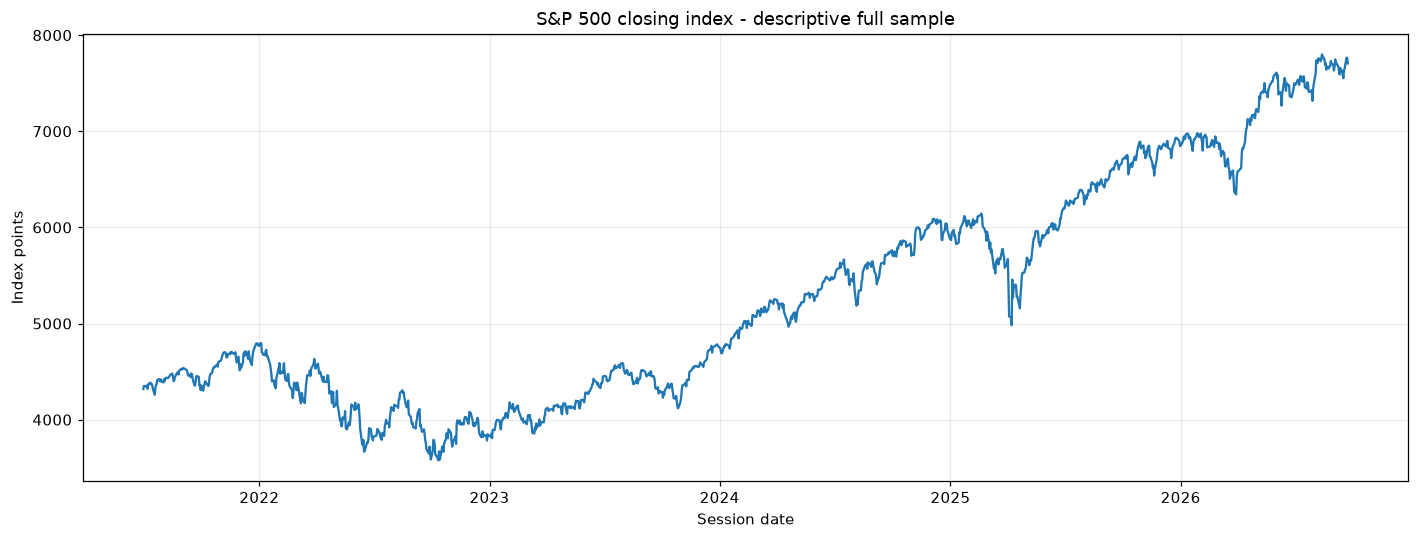

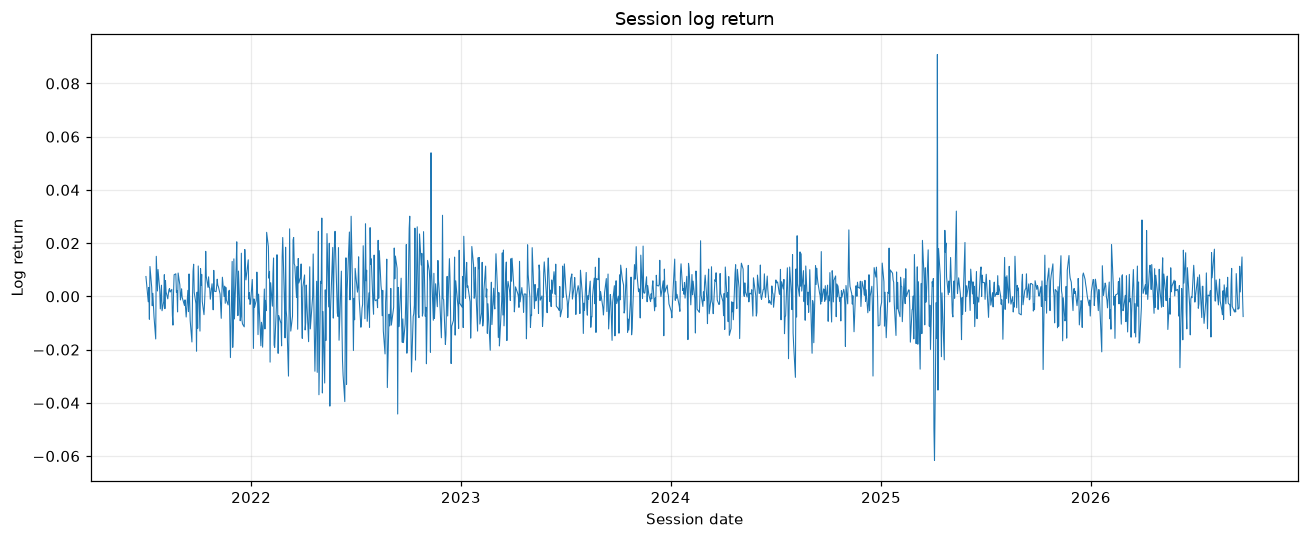

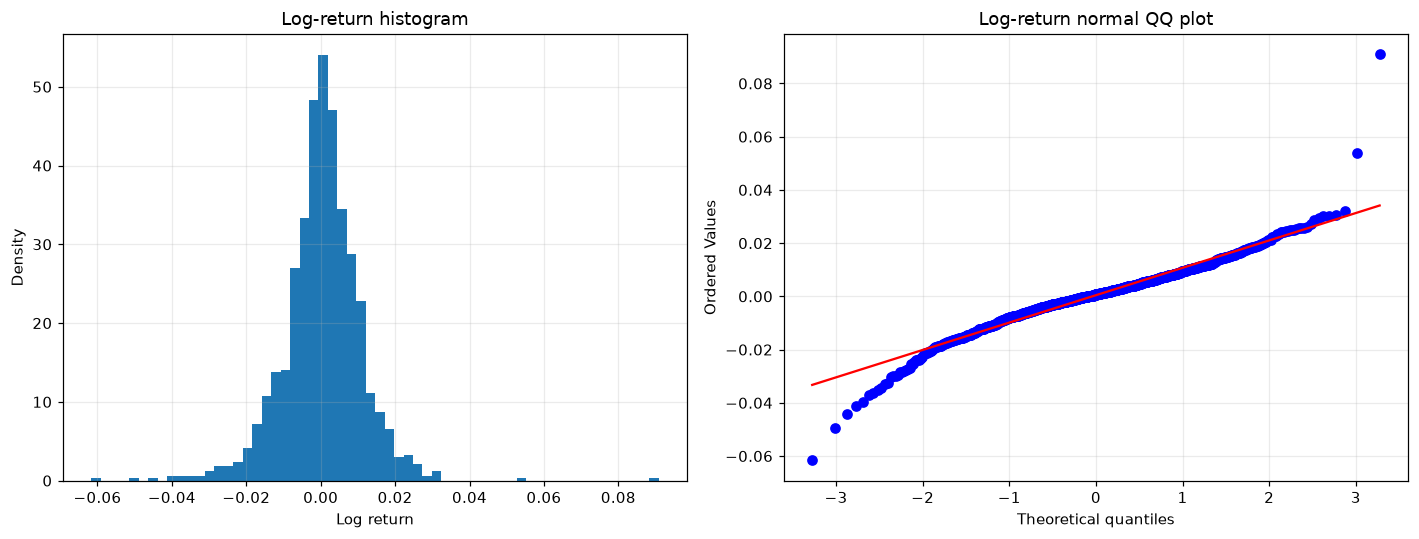

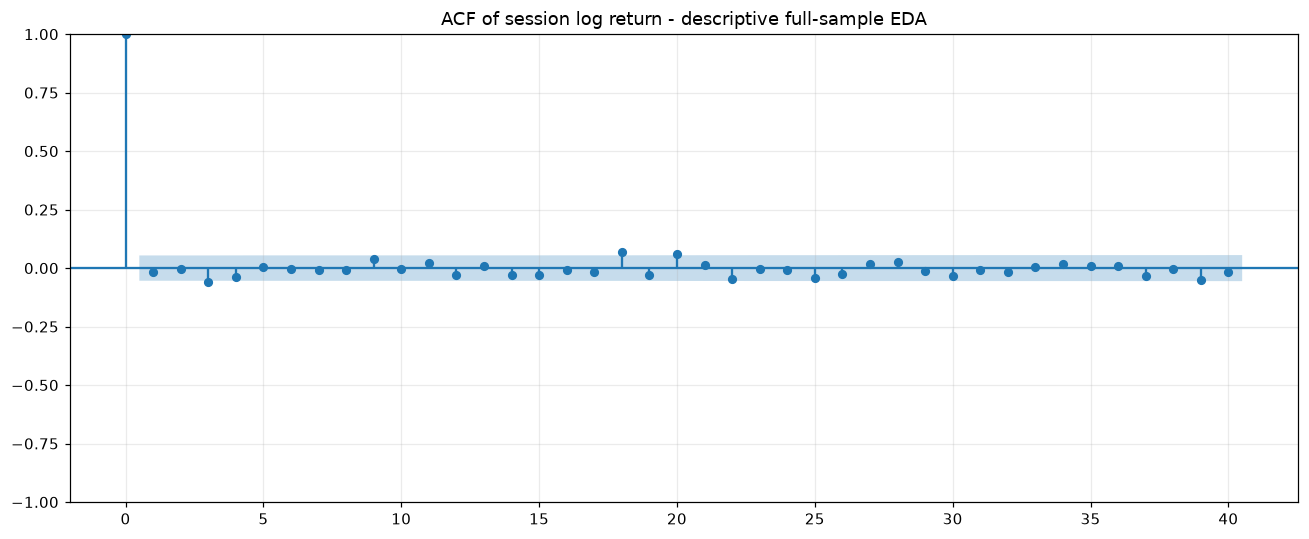

In [3]:
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(df.index,df['Price'])
ax.set(title='S&P 500 closing index - descriptive full sample',ylabel='Index points',xlabel='Session date')
save_figure(fig,'01_raw_index.png')
fig, ax = plt.subplots()
ax.plot(log_ret,linewidth=0.7)
ax.set(title='Session log return',ylabel='Log return',xlabel='Session date')
save_figure(fig,'02_log_return.png')
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].hist(log_ret.dropna(),bins=60,density=True)
axes[0].set(title='Log-return histogram',xlabel='Log return',ylabel='Density')
stats.probplot(log_ret.dropna(),dist='norm',plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig,'03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(),lags=40,ax=ax)
ax.set_title('ACF of session log return - descriptive full-sample EDA')
save_figure(fig,'04_acf_log_return.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'index points'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,index points,index points,index points
Start,2021-07-01,2021-07-01,2025-09-08
End,2026-09-23,2025-09-05,2026-09-23
Count,1313,1050,263
Mean,5266.721813,4812.506895,7080.127376
SD,1151.885882,768.299998,391.319242
Min,3577.03,3577.03,6343.72
Q1,4328.87,4179.7775,6773.155
Median,4975.51,4538.295,6929.94
Q3,6074.08,5501.4375,7465.24


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-09-08
End,2026-09-23,2025-09-05,2026-09-23
Count,1312,1049,263
Mean,0.000441,0.000387,0.000658
SD,0.010572,0.011119,0.00804
Min,-0.061609,-0.061609,-0.027486
Q1,-0.00472,-0.00506,-0.003815
Median,0.000731,0.000721,0.000759
Q3,0.006177,0.006369,0.005774


## Step 4 - Chronological Split BEFORE Scaling and Windowing


,split,start_date,end_date,n_sessions,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-09-05,1050,3577.03,6502.08,4812.506895,1049,0.000387,0.011119
1,Test,2025-09-08,2026-09-23,263,6343.72,7798.99,7080.127376,263,0.000658,0.008040


Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).


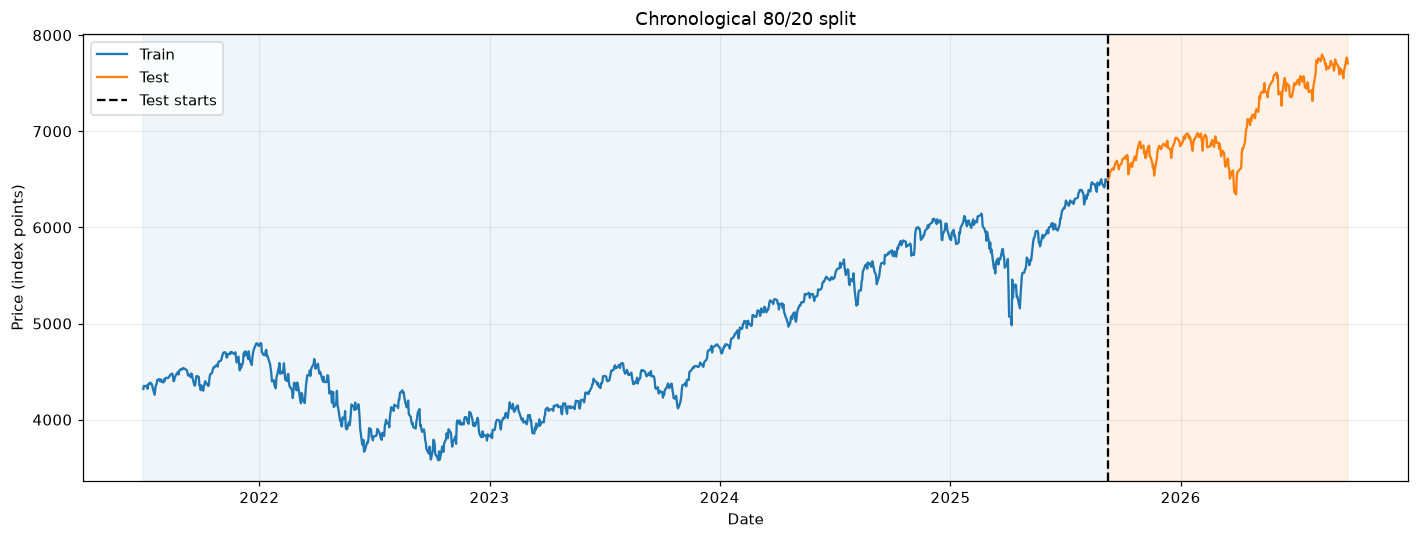

In [4]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert n_train-LOOKBACK-MAX_H > 0 and n_test >= MAX_H
assert df.index[TRAIN_END_IDX] < df.index[n_train]
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_sessions=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (index points)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')

## Step 5 - Scaling (fit on Train returns only)

Fit the StandardScaler only on valid return indices 1..n_train-1. The first missing return is structural. Transform Test inputs with the frozen Train mean/SD; Test never contributes to fitting.

In [5]:
scaler_fit_indices = np.arange(1, n_train)
assert scaler_fit_indices.max() <= TRAIN_END_IDX
scaler = StandardScaler()
scaler.fit(train_ret.to_numpy().reshape(-1, 1))
assert int(scaler.n_samples_seen_) == len(scaler_fit_indices)
assert train_ret.index.max() <= df.index[TRAIN_END_IDX]
scaler_mean = float(scaler.mean_[0])
scaler_std = float(scaler.scale_[0])
assert scaler_std > 0
np.testing.assert_allclose(scaler_mean, train_ret.mean(), atol=1e-12)
np.testing.assert_allclose(scaler_std, train_ret.std(ddof=0), atol=1e-12)
z = np.full(n, np.nan, dtype=np.float64)
z[1:] = scaler.transform(log_ret.iloc[1:].to_numpy().reshape(-1, 1)).ravel()
assert np.isnan(z[0]) and np.isfinite(z[1:]).all()
scaler_params = dict(mean=scaler_mean, std=scaler_std, ddof=0,
    fit_first_index=int(scaler_fit_indices.min()), fit_last_index=int(scaler_fit_indices.max()),
    n_samples=int(scaler.n_samples_seen_), fit_end_date=str(train_ret.index[-1].date()))
print('Frozen scaler:', scaler_params)
frozen_scaler_hash = scaler_digest(scaler)
save_table(pd.DataFrame([scaler_params]),"scaler_provenance.csv")

Frozen scaler: {'mean': 0.00038676807551764895, 'std': 0.011113592303050979, 'ddof': 0, 'fit_first_index': 1, 'fit_last_index': 1049, 'n_samples': 1049, 'fit_end_date': '2025-09-05'}


## Step 6 - MIMO Train windows

X contains LOOKBACK=60 scaled session returns through origin t; y contains the next MAX_H=30 individual scaled returns. All inputs and targets stay inside Train; no validation windows. Window counts are computed from this dataset.

In [6]:
train_origins = np.arange(LOOKBACK, TRAIN_END_IDX - MAX_H + 1)
train_input_indices = train_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
train_target_indices = train_origins[:, None] + np.arange(1, MAX_H+1)[None, :]
assert train_input_indices.min() >= 1
assert train_input_indices.max() <= TRAIN_END_IDX
assert train_target_indices.max() <= TRAIN_END_IDX
assert (train_input_indices < n_train).all() and (train_target_indices < n_train).all()
X_train = z[train_input_indices][..., None].astype(np.float32)
y_train = z[train_target_indices].astype(np.float32)
assert X_train.shape == (len(train_origins), LOOKBACK, 1)
assert y_train.shape == (len(train_origins), MAX_H)
assert len(train_origins) == TRAIN_END_IDX - MAX_H - LOOKBACK + 1
assert np.isfinite(X_train).all() and np.isfinite(y_train).all()
window_audit = pd.DataFrame(dict(origin_idx=train_origins, origin_date=df.index[train_origins],
    input_start_idx=train_input_indices[:, 0], input_end_idx=train_input_indices[:, -1],
    target_start_idx=train_target_indices[:, 0], target_end_idx=train_target_indices[:, -1]))
save_table(window_audit, 'training_window_audit.csv')
print('Training samples:', len(train_origins), 'X:', X_train.shape, 'y:', y_train.shape)
display(window_audit.iloc[[0,-1]])

Training samples: 960 X: (960, 60, 1) y: (960, 30)


,origin_idx,origin_date,input_start_idx,input_end_idx,target_start_idx,target_end_idx
0,60,2021-09-27,1,60,61,90
959,1019,2025-07-24,960,1019,1020,1049


## Step 7 - Fixed Architecture (No Tuning)


In [7]:
def build_model():
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        LSTM(64, activation='tanh', return_sequences=True),
        Dropout(DROPOUT),
        LSTM(32, activation='tanh'),
        Dropout(DROPOUT),
        Dense(MAX_H)
    ])
    model.compile(optimizer=Adam(learning_rate=LR), loss='mse')
    return model
preview_model = build_model()
architecture_lines = []
preview_model.summary(print_fn=lambda text, **kwargs: architecture_lines.append(text))
architecture_text = '\n'.join(architecture_lines)
print(architecture_text)
model_config = dict(horizons=HORIZONS, max_h=MAX_H, train_ratio=TRAIN_RATIO, lookback=LOOKBACK,
    epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=LR, dropout=DROPOUT, seeds=SEEDS,
    architecture=['LSTM(64,tanh,return_sequences=True)','Dropout(0.1)',
                  'LSTM(32,tanh)','Dropout(0.1)','Dense(30)'], validation=False,
    target='session_log_return', input='Price only', ensemble='mean of seed log-return forecasts')
del preview_model

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 30)             │           990 │
└─────────────────────────────────┴─────────────────────

## Step 8 - Training Once per Seed, Without Validation
Exactly 50 epochs per seed, fixed settings, no callbacks or early stopping.
`shuffle=True` reorders training samples only; it never changes temporal order inside a window or the chronological raw split.
Training-loss reduction is a process check, not evidence of out-of-sample accuracy. No seed is selected or discarded using test performance.


Training seed 0: 50 fixed epochs


Finished seed 0: loss 1.05701 -> 0.86558


Training seed 1: 50 fixed epochs


Finished seed 1: loss 1.05683 -> 0.87190


Training seed 2: 50 fixed epochs


...

Training seed 3: 50 fixed epochs


Finished seed 3: loss 1.05715 -> 0.88269


Training seed 4: 50 fixed epochs


Finished seed 4: loss 1.05732 -> 0.88145


,seed,first_loss,final_loss,loss_reduced,epochs,seconds
0,0,1.057008,0.865584,True,50,57.277978
1,1,1.056835,0.871898,True,50,56.503502
2,2,1.057393,0.891069,True,50,57.163841
3,3,1.057148,0.882686,True,50,40.597464
4,4,1.057317,0.881453,True,50,31.294709


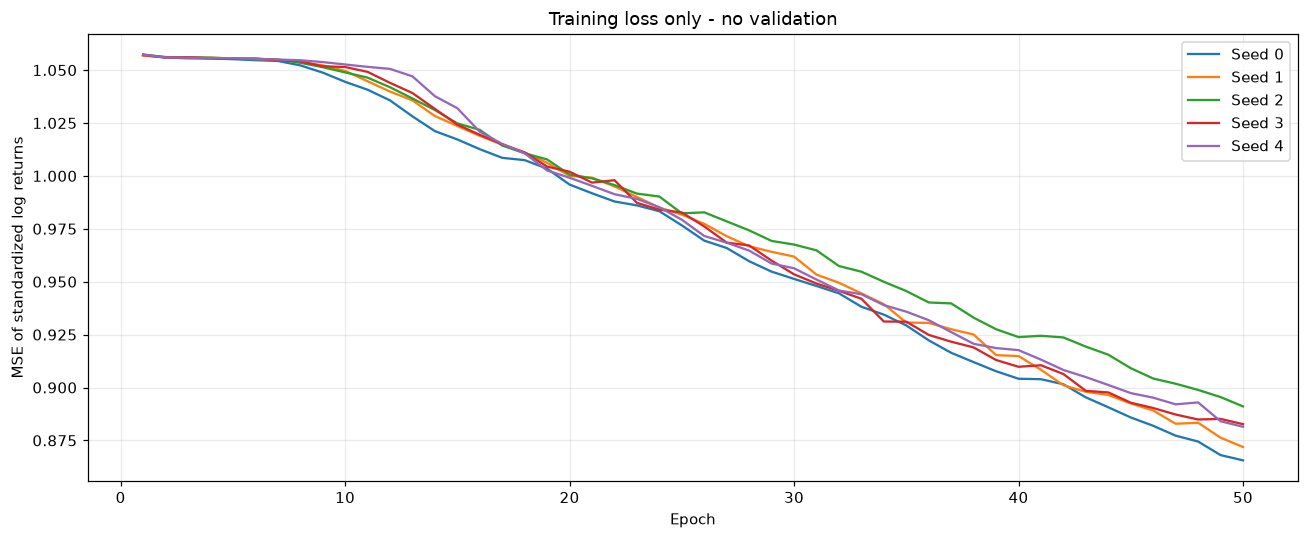

In [8]:
models, frozen_weight_hashes, training_rows, training_audit_rows = {}, {}, [], []
for seed in SEEDS:
    tf.keras.backend.clear_session()
    set_seed(seed)
    model = build_model()
    started = time.perf_counter()
    print(f'Training seed {seed}: {EPOCHS} fixed epochs', flush=True)
    history = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0)
    loss = np.asarray(history.history['loss'], dtype=float)
    assert len(loss) == EPOCHS and np.isfinite(loss).all()
    model.trainable = False
    models[seed] = model
    frozen_weight_hashes[seed] = weights_digest(model)
    training_rows.extend(dict(seed=seed, epoch=epoch, loss=value)
                         for epoch, value in enumerate(loss, 1))
    training_audit_rows.append(dict(seed=seed, first_loss=loss[0], final_loss=loss[-1],
        loss_reduced=bool(loss[-1] < loss[0]), epochs=len(loss), seconds=time.perf_counter()-started,
        weights_sha256=frozen_weight_hashes[seed]))
    save_table(pd.DataFrame(training_rows), 'training_loss.csv')
    save_table(pd.DataFrame(training_audit_rows), 'training_audit.csv')
    print(f'Finished seed {seed}: loss {loss[0]:.5f} -> {loss[-1]:.5f}', flush=True)
training_loss = pd.DataFrame(training_rows)
training_audit = pd.DataFrame(training_audit_rows)
display(training_audit.drop(columns='weights_sha256'))
fig, ax = plt.subplots()
for seed in SEEDS:
    curve = training_loss.loc[training_loss['seed'].eq(seed)]
    ax.plot(curve['epoch'], curve['loss'], label=f'Seed {seed}')
ax.set(title='Training loss only - no validation', xlabel='Epoch', ylabel='MSE of standardized log returns')
ax.legend()
save_figure(fig, '06_training_loss.png')

## Step 9 - Rolling-origin Forecasts with Fixed Weights
Origins in test evaluation are n_train-1..n-2. Each 60-return input ends at its own origin; later actual returns never enter that origin's 30-step MIMO output.
Each seed predicts all inputs in one batch operation. Inputs for different origins remain independent (the LSTMs are not stateful).
Average predicted log returns across all five seeds, then compound the first h returns from the observed origin price. Averaging log returns is not the same as averaging the resulting seed prices.
The extra last input is for future forecasting only; it cannot contribute target values to test evaluation.


In [9]:
assert scaler_digest(scaler)==frozen_scaler_hash
test_origins = np.arange(TRAIN_END_IDX, n-1)
inference_origins = np.r_[test_origins, n-1]
inference_input_indices = inference_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
assert len(test_origins) == n_test
assert inference_input_indices.min() >= 1
assert (inference_input_indices <= inference_origins[:, None]).all()
X_inference = z[inference_input_indices][..., None].astype(np.float32)
assert X_inference.shape == (n_test+1, LOOKBACK, 1) and np.isfinite(X_inference).all()
return_predictions = []
weight_audit_rows = []
for seed in SEEDS:
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    predicted_z = models[seed].predict(X_inference, batch_size=BATCH_SIZE, verbose=0).astype(np.float64)
    assert predicted_z.shape == (len(inference_origins), MAX_H)
    predicted_returns = predicted_z * scaler_std + scaler_mean
    np.testing.assert_allclose(predicted_returns,
        scaler.inverse_transform(predicted_z.reshape(-1,1)).reshape(predicted_z.shape), atol=1e-12)
    return_predictions.append(predicted_returns)
    after = weights_digest(models[seed])
    assert after == frozen_weight_hashes[seed], 'Weights changed during inference'
    weight_audit_rows.append(dict(seed=seed, train_hash=frozen_weight_hashes[seed],
        after_predict_hash=after, unchanged=after == frozen_weight_hashes[seed]))
return_predictions = np.stack(return_predictions, axis=0)
return_predictions_ens = return_predictions.mean(axis=0)
origin_prices = df['Price'].iloc[inference_origins].to_numpy()
seed_prices = origin_prices[None, :, None] * np.exp(np.cumsum(return_predictions, axis=2))
ensemble_prices = origin_prices[:, None] * np.exp(np.cumsum(return_predictions_ens, axis=1))
forecast_rows = []
for h in HORIZONS:
    eligible = np.flatnonzero(test_origins + h < n)
    for pos in eligible:
        origin = int(test_origins[pos])
        target = origin + h
        row = dict(origin_date=df.index[origin], h=h, target_date=df.index[target],
            price_origin=df['Price'].iloc[origin], actual=df['Price'].iloc[target],
            lstm_fc_ens=ensemble_prices[pos, h-1])
        row.update({f'lstm_fc_seed{seed}': seed_prices[k, pos, h-1] for k,seed in enumerate(SEEDS)})
        forecast_rows.append(row)
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict() == {h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert (forecasts['target_date'] >= df.index[n_train]).all()
assert (df.index.get_indexer(forecasts['target_date'])-df.index.get_indexer(forecasts['origin_date'])==forecasts['h'].to_numpy()).all()
save_table(forecasts, 'forecasts_long.csv')
weight_audit = pd.DataFrame(weight_audit_rows)
save_table(weight_audit, 'weights_fixed_audit.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())
assert scaler_digest(scaler)==frozen_scaler_hash

,n_points
h,
1,263
3,261
5,259
7,257
14,250
21,243
30,234


### 9.1 Test Forecast Tables by Horizon
Every row has one origin, one target date h trading sessions later, the actual target price, and ensemble/seed forecasts in index points.
These tables support the historical test evaluation below; they do not contain dates beyond the CSV.


In [10]:
for h in HORIZONS:
    horizon_forecasts = forecasts.loc[forecasts['h'].eq(h)].copy()
    save_table(horizon_forecasts, f'forecasts_h{h}.csv')
    display(Markdown(f'**h = {h} trading sessions: {len(horizon_forecasts)} test forecasts**'))
    show_scroll_table(horizon_forecasts)

**h = 1 trading sessions: 263 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-09-05,1,2025-09-08,"6,481.5000","6,495.1500","6,488.0290","6,485.8614","6,499.0868","6,482.8535","6,485.5570","6,486.7987"
2025-09-08,1,2025-09-09,"6,495.1500","6,512.6100","6,499.0693","6,495.8441","6,506.7671","6,493.1435","6,499.9998","6,499.6000"
2025-09-09,1,2025-09-10,"6,512.6100","6,532.0400","6,513.9938","6,510.8216","6,519.1852","6,506.7157","6,516.1975","6,517.0568"
2025-09-10,1,2025-09-11,"6,532.0400","6,587.4700","6,529.8523","6,529.3780","6,529.4923","6,521.5140","6,534.7478","6,534.1381"
2025-09-11,1,2025-09-12,"6,587.4700","6,584.2900","6,579.7391","6,578.5198","6,579.0727","6,568.7908","6,584.8603","6,587.4675"
2025-09-12,1,2025-09-15,"6,584.2900","6,615.2800","6,575.1669","6,575.0927","6,572.0840","6,566.6825","6,578.4956","6,583.4919"
2025-09-15,1,2025-09-16,"6,615.2800","6,606.7600","6,605.0753","6,604.3879","6,602.2776","6,598.0337","6,606.6361","6,614.0518"
2025-09-16,1,2025-09-17,"6,606.7600","6,600.3500","6,597.9804","6,596.3904","6,595.9486","6,593.6758","6,596.8243","6,607.0709"
2025-09-17,1,2025-09-18,"6,600.3500","6,631.9600","6,593.2241","6,593.2020","6,593.3010","6,585.5773","6,591.4690","6,602.5825"
2025-09-18,1,2025-09-19,"6,631.9600","6,664.3600","6,625.7121","6,627.9056","6,628.2077","6,613.9340","6,624.0859","6,634.4443"


**h = 3 trading sessions: 261 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-09-05,3,2025-09-10,"6,481.5000","6,532.0400","6,499.2012","6,490.4551","6,518.9018","6,487.4779","6,499.5881","6,499.6294"
2025-09-08,3,2025-09-11,"6,495.1500","6,587.4700","6,504.8461","6,494.4818","6,518.1230","6,489.3415","6,511.6365","6,510.6940"
2025-09-09,3,2025-09-12,"6,512.6100","6,584.2900","6,513.7765","6,501.7787","6,522.9523","6,494.9185","6,521.8387","6,527.4586"
2025-09-10,3,2025-09-15,"6,532.0400","6,615.2800","6,524.0296","6,520.3397","6,520.6407","6,504.3466","6,534.1157","6,540.7660"
2025-09-11,3,2025-09-16,"6,587.4700","6,606.7600","6,562.5141","6,554.3504","6,559.7776","6,534.7835","6,573.5250","6,590.2662"
2025-09-12,3,2025-09-17,"6,584.2900","6,600.3500","6,559.5177","6,554.8575","6,552.0477","6,542.4933","6,562.8958","6,585.3737"
2025-09-15,3,2025-09-18,"6,615.2800","6,631.9600","6,590.5294","6,585.2717","6,583.5029","6,578.1360","6,590.0187","6,615.7834"
2025-09-16,3,2025-09-19,"6,606.7600","6,664.3600","6,590.1224","6,584.7742","6,584.7682","6,584.9539","6,584.5937","6,611.5656"
2025-09-17,3,2025-09-22,"6,600.3500","6,693.7500","6,591.3361","6,593.2808","6,590.7491","6,576.5147","6,586.2063","6,609.9748"
2025-09-18,3,2025-09-23,"6,631.9600","6,656.9200","6,625.0912","6,634.3746","6,628.6051","6,599.0604","6,621.7910","6,641.7055"


**h = 5 trading sessions: 259 test forecasts**

...

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-09-05,14,2025-09-25,"6,481.5000","6,604.7200","6,433.9998","6,377.9019","6,408.1666","6,397.2654","6,455.1920","6,532.6599"
2025-09-08,14,2025-09-26,"6,495.1500","6,643.7000","6,456.1042","6,396.7060","6,453.6565","6,401.2023","6,486.9053","6,543.2168"
2025-09-09,14,2025-09-29,"6,512.6100","6,661.2100","6,471.0329","6,414.8458","6,474.3977","6,411.2193","6,500.0740","6,555.7671"
2025-09-10,14,2025-09-30,"6,532.0400","6,688.4600","6,520.8760","6,468.8582","6,553.3645","6,466.5931","6,545.8025","6,570.5139"
2025-09-11,14,2025-10-01,"6,587.4700","6,711.2000","6,557.9630","6,509.0205","6,589.0095","6,480.6952","6,594.9334","6,617.2424"
2025-09-12,14,2025-10-02,"6,584.2900","6,715.3500","6,586.6172","6,538.2535","6,626.7343","6,541.2506","6,614.7703","6,612.6454"
2025-09-15,14,2025-10-03,"6,615.2800","6,715.7900","6,632.5880","6,589.3155","6,676.8618","6,599.6646","6,656.2034","6,641.3134"
2025-09-16,14,2025-10-06,"6,606.7600","6,740.2800","6,644.0739","6,608.2836","6,689.3819","6,626.2421","6,662.5282","6,634.2408"
2025-09-17,14,2025-10-07,"6,600.3500","6,714.5900","6,639.6156","6,613.2006","6,700.1445","6,599.1818","6,657.1664","6,628.8670"
2025-09-18,14,2025-10-08,"6,631.9600","6,753.7200","6,663.6890","6,645.9174","6,736.9600","6,605.9982","6,673.6695","6,656.5858"


**h = 21 trading sessions: 243 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-09-05,21,2025-10-06,"6,481.5000","6,740.2800","6,506.5623","6,414.5487","6,545.9377","6,428.6631","6,570.6682","6,574.9095"
2025-09-08,21,2025-10-07,"6,495.1500","6,714.5900","6,535.7210","6,448.2856","6,597.8902","6,451.2147","6,595.6990","6,587.4276"
2025-09-09,21,2025-10-08,"6,512.6100","6,753.7200","6,557.3221","6,480.0332","6,626.6409","6,475.4215","6,604.8410","6,601.3309"
2025-09-10,21,2025-10-09,"6,532.0400","6,735.1100","6,604.8247","6,544.4673","6,693.1299","6,544.3975","6,627.8013","6,615.5169"
2025-09-11,21,2025-10-10,"6,587.4700","6,552.5100","6,642.9471","6,586.6277","6,738.1136","6,567.2741","6,664.6810","6,659.4446"
2025-09-12,21,2025-10-13,"6,584.2900","6,654.7200","6,660.8386","6,614.6449","6,758.4575","6,625.9572","6,655.4040","6,650.7006"
2025-09-15,21,2025-10-14,"6,615.2800","6,644.3100","6,698.6281","6,659.1640","6,798.8310","6,678.8801","6,681.5071","6,675.7076"
2025-09-16,21,2025-10-15,"6,606.7600","6,671.0600","6,701.8379","6,672.9239","6,799.5551","6,693.3566","6,676.7230","6,667.5398"
2025-09-17,21,2025-10-16,"6,600.3500","6,629.0700","6,695.9081","6,675.9235","6,803.4122","6,662.9683","6,674.1067","6,664.2059"
2025-09-18,21,2025-10-17,"6,631.9600","6,664.0100","6,721.2191","6,707.8198","6,837.7515","6,667.0314","6,699.5048","6,695.3049"


**h = 30 trading sessions: 234 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-09-05,30,2025-10-17,"6,481.5000","6,664.0100","6,546.4460","6,542.3952","6,613.8972","6,453.4759","6,542.5558","6,581.0108"
2025-09-08,30,2025-10-20,"6,495.1500","6,735.1300","6,566.3356","6,567.5709","6,657.0629","6,457.7506","6,557.2101","6,593.6758"
2025-09-09,30,2025-10-21,"6,512.6100","6,735.3500","6,581.4841","6,593.2318","6,673.2372","6,477.6289","6,553.9444","6,610.9744"
2025-09-10,30,2025-10-22,"6,532.0400","6,699.4000","6,616.2157","6,632.2536","6,748.9525","6,512.8619","6,563.5652","6,625.8120"
2025-09-11,30,2025-10-23,"6,587.4700","6,738.4400","6,652.0280","6,681.9022","6,783.2683","6,534.0529","6,589.5978","6,674.0535"
2025-09-12,30,2025-10-24,"6,584.2900","6,791.6900","6,670.6001","6,690.3580","6,819.9336","6,578.6369","6,593.1123","6,673.7297"
2025-09-15,30,2025-10-27,"6,615.2800","6,875.1600","6,713.6252","6,724.3916","6,869.2867","6,626.9220","6,642.6906","6,707.5657"
2025-09-16,30,2025-10-28,"6,606.7600","6,890.8900","6,723.7812","6,726.6981","6,883.0845","6,638.5491","6,664.3568","6,708.9012"
2025-09-17,30,2025-10-29,"6,600.3500","6,890.5900","6,719.3262","6,715.8664","6,893.6236","6,599.3101","6,682.1066","6,709.1432"
2025-09-18,30,2025-10-30,"6,631.9600","6,822.3400","6,743.0785","6,733.5006","6,929.2080","6,593.5204","6,722.7447","6,740.6629"


### 9.2 Future Forecasts from the Latest Observed Date
The final inference input ends on the last date in the CSV. The same fixed seed weights and frozen scaler predict all requested future horizons.
There are no future actual values in the source, so these rows are excluded from RMSE/MAPE. Seed disagreement is not a calibrated prediction interval.


In [11]:
assert scaler_digest(scaler)==frozen_scaler_hash
future_rows = []
latest_origin = df.index[-1]
for h in HORIZONS:
    row = dict(origin_date=latest_origin, h=h, target_date=future_dates[h-1],
        price_origin=float(df['Price'].iloc[-1]), lstm_fc_ens=ensemble_prices[-1,h-1])
    row.update({f'lstm_fc_seed{seed}': seed_prices[k,-1,h-1] for k,seed in enumerate(SEEDS)})
    future_rows.append(row)
future_forecasts = pd.DataFrame(future_rows)
assert (future_forecasts['target_date'] > df.index[-1]).all()
save_table(future_forecasts, 'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)
assert scaler_digest(scaler)==frozen_scaler_hash

origin_date,h,target_date,price_origin,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2026-09-23,1,2026-09-24,"7,706.0300","7,679.7191","7,735.4936","7,641.0061","7,671.1110","7,686.2971","7,665.0089"
2026-09-23,3,2026-09-28,"7,706.0300","7,626.3107","7,789.1592","7,525.3660","7,597.6298","7,646.2893","7,575.7460"
2026-09-23,5,2026-09-30,"7,706.0300","7,606.0707","7,808.6686","7,509.1634","7,583.0106","7,626.1050","7,507.3870"
2026-09-23,7,2026-10-02,"7,706.0300","7,632.4086","7,807.9963","7,532.0438","7,621.8167","7,646.7654","7,556.4770"
2026-09-23,14,2026-10-13,"7,706.0300","7,842.7830","8,028.4858","7,730.4865","7,884.2347","7,797.2070","7,776.9965"
2026-09-23,21,2026-10-22,"7,706.0300","7,718.9644","7,957.2839","7,575.8860","7,781.4180","7,699.7613","7,586.8397"
2026-09-23,30,2026-11-04,"7,706.0300","7,607.6137","7,766.6047","7,654.5024","7,562.1134","7,598.7513","7,459.4819"


### 9.3 Daily future forecast tables - next 7 and 30 steps

Horizons count NYSE trading sessions and retain the existing holiday calendar.

Uses the existing fixed Train MIMO path, with ensemble and per-seed forecasts. Seed spread is not a calibrated prediction interval.

Both complete tables are embedded below and retained via the existing notebook-only save_table helper.


In [12]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
# Reuse the full MIMO price path, averaging predicted daily returns before compounding.
assert scaler_digest(scaler) == frozen_scaler_hash
future_forecast_daily['lstm_fc_ens'] = ensemble_prices[-1, :daily_steps]
for k, seed in enumerate(SEEDS):
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    future_forecast_daily[f'lstm_fc_seed{seed}'] = seed_prices[k, -1, :daily_steps]
daily_forecast_columns = ['lstm_fc_ens', *[f'lstm_fc_seed{seed}' for seed in SEEDS]]
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['lstm_fc_ens']],
    future_forecasts.set_index('h').loc[HORIZONS, ['lstm_fc_ens']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} NYSE trading sessions - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} index points**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all(f'future_forecast_daily_{days}d.csv' in notebook_tables for days in DAILY_FORECAST_WINDOWS)


**Next 7 NYSE trading sessions - origin 2026-09-23, last observed price 7,706.030000 index points**

origin_date,h,target_date,day_of_week,price_origin,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2026-09-23,1,2026-09-24,Thursday,"7,706.030000","7,679.719109","7,735.493630","7,641.006129","7,671.111023","7,686.297057","7,665.008916"
2026-09-23,2,2026-09-25,Friday,"7,706.030000","7,647.618999","7,765.643861","7,566.108524","7,624.667588","7,665.394472","7,617.733191"
2026-09-23,3,2026-09-28,Monday,"7,706.030000","7,626.310683","7,789.159247","7,525.366022","7,597.629814","7,646.289295","7,575.745959"
2026-09-23,4,2026-09-29,Tuesday,"7,706.030000","7,613.562272","7,799.596333","7,510.375764","7,588.615662","7,636.458476","7,536.178486"
2026-09-23,5,2026-09-30,Wednesday,"7,706.030000","7,606.070715","7,808.668556","7,509.163421","7,583.010627","7,626.105022","7,507.386972"
2026-09-23,6,2026-10-01,Thursday,"7,706.030000","7,612.703153","7,809.088511","7,511.488903","7,595.764872","7,630.833606","7,520.117139"
2026-09-23,7,2026-10-02,Friday,"7,706.030000","7,632.408621","7,807.996296","7,532.043805","7,621.816740","7,646.765391","7,556.476972"


**Next 30 NYSE trading sessions - origin 2026-09-23, last observed price 7,706.030000 index points**

origin_date,h,target_date,day_of_week,price_origin,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2026-09-23,1,2026-09-24,Thursday,"7,706.030000","7,679.719109","7,735.493630","7,641.006129","7,671.111023","7,686.297057","7,665.008916"
2026-09-23,2,2026-09-25,Friday,"7,706.030000","7,647.618999","7,765.643861","7,566.108524","7,624.667588","7,665.394472","7,617.733191"
2026-09-23,3,2026-09-28,Monday,"7,706.030000","7,626.310683","7,789.159247","7,525.366022","7,597.629814","7,646.289295","7,575.745959"
2026-09-23,4,2026-09-29,Tuesday,"7,706.030000","7,613.562272","7,799.596333","7,510.375764","7,588.615662","7,636.458476","7,536.178486"
2026-09-23,5,2026-09-30,Wednesday,"7,706.030000","7,606.070715","7,808.668556","7,509.163421","7,583.010627","7,626.105022","7,507.386972"
2026-09-23,6,2026-10-01,Thursday,"7,706.030000","7,612.703153","7,809.088511","7,511.488903","7,595.764872","7,630.833606","7,520.117139"
2026-09-23,7,2026-10-02,Friday,"7,706.030000","7,632.408621","7,807.996296","7,532.043805","7,621.816740","7,646.765391","7,556.476972"
2026-09-23,8,2026-10-05,Monday,"7,706.030000","7,659.124697","7,810.044155","7,565.038410","7,675.287174","7,662.925293","7,584.760109"
2026-09-23,9,2026-10-06,Tuesday,"7,706.030000","7,696.942134","7,833.108228","7,612.253798","7,718.325046","7,685.401814","7,637.550208"
2026-09-23,10,2026-10-07,Wednesday,"7,706.030000","7,733.498932","7,874.131421","7,644.756746","7,759.906463","7,708.694506","7,682.038836"


## Step 10 - Evaluation: LSTM Only, RMSE and MAPE
Metrics use actual and predicted index points prices on aligned test target dates.
The main table evaluates the ensemble. The seed table evaluates each seed independently, then reports sample mean and SD (ddof=1) across the five seeds.
Sanity checks stop on nonfinite, nonpositive forecasts rather than clipping or changing model settings.


In [13]:
forecast_columns = ['lstm_fc_ens', *[f'lstm_fc_seed{seed}' for seed in SEEDS]]
for name, frame in [('test', forecasts), ('future', future_forecasts)]:
    values = frame[forecast_columns].to_numpy()
    bad = (~np.isfinite(values)) | (values <= 0)
    if bad.any():
        bad_rows = frame.loc[bad.any(axis=1)].copy()
        print(f'Invalid {name} forecasts; stop without clipping or retuning.')
        display(bad_rows)
        save_table(bad_rows, f'forecast_sanity_failures_{name}.csv')
    assert not bad.any(), f'{name} forecasts fail the specified finite positive-price domain checks'

def rmse(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    return float(np.sqrt(np.mean((actual-fc)**2)))
def mape(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    assert (actual > 0).all()
    return float(100*np.mean(np.abs((actual-fc)/actual)))
evaluation_rows, seed_rows = [], []
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    evaluation_rows.append(dict(h=h, n_points=len(group),
        RMSE=rmse(group['actual'], group['lstm_fc_ens']), MAPE=mape(group['actual'], group['lstm_fc_ens'])))
    for seed in SEEDS:
        seed_rows.append(dict(h=h, seed=seed, RMSE=rmse(group['actual'], group[f'lstm_fc_seed{seed}']),
                              MAPE=mape(group['actual'], group[f'lstm_fc_seed{seed}'])))
evaluation = pd.DataFrame(evaluation_rows)
evaluation_seed_individual = pd.DataFrame(seed_rows)
seed_summary_rows, seed_export_rows = [], []
for h in HORIZONS:
    group = evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h)]
    mean = group[['RMSE','MAPE']].mean()
    sd = group[['RMSE','MAPE']].std(ddof=1)
    seed_summary_rows.append(dict(h=h, RMSE_mean=mean['RMSE'], RMSE_SD=sd['RMSE'],
                                  MAPE_mean=mean['MAPE'], MAPE_SD=sd['MAPE']))
    seed_export_rows.extend(group.to_dict('records'))
    seed_export_rows.extend([dict(h=h, seed='mean', **mean.to_dict()), dict(h=h, seed='SD', **sd.to_dict())])
seed_summary = pd.DataFrame(seed_summary_rows)
evaluation_by_seed = pd.DataFrame(seed_export_rows)
assert evaluation['h'].tolist() == HORIZONS
save_table(evaluation, 'evaluation_by_horizon.csv')
save_table(evaluation_by_seed, 'evaluation_by_seed.csv')
print('Ensemble RMSE (index points), MAPE (%):')
display(evaluation.style.format({'RMSE':'{:,.2f}', 'MAPE':'{:.2f}'}).hide(axis='index'))
print('Mean and SD across seeds (not ensemble metrics):')
display(seed_summary)

Ensemble RMSE (index points), MAPE (%):


h,n_points,RMSE,MAPE
1,263,60.85,0.65
3,261,116.04,1.25
5,259,149.19,1.61
7,257,178.31,1.93
14,250,254.90,2.74
21,243,278.59,3.00
30,234,297.42,3.12


Mean and SD across seeds (not ensemble metrics):


,h,RMSE_mean,RMSE_SD,MAPE_mean,MAPE_SD
0,1,62.673426,2.025892,0.672592,0.017091
1,3,122.869586,7.509389,1.308549,0.073654
2,5,158.867868,10.931224,1.699004,0.101540
3,7,189.733665,15.458478,2.029030,0.122342
4,14,270.482724,28.090451,2.894732,0.241264
5,21,299.028623,40.252269,3.186447,0.328508
6,30,325.796255,53.048649,3.494699,0.550007


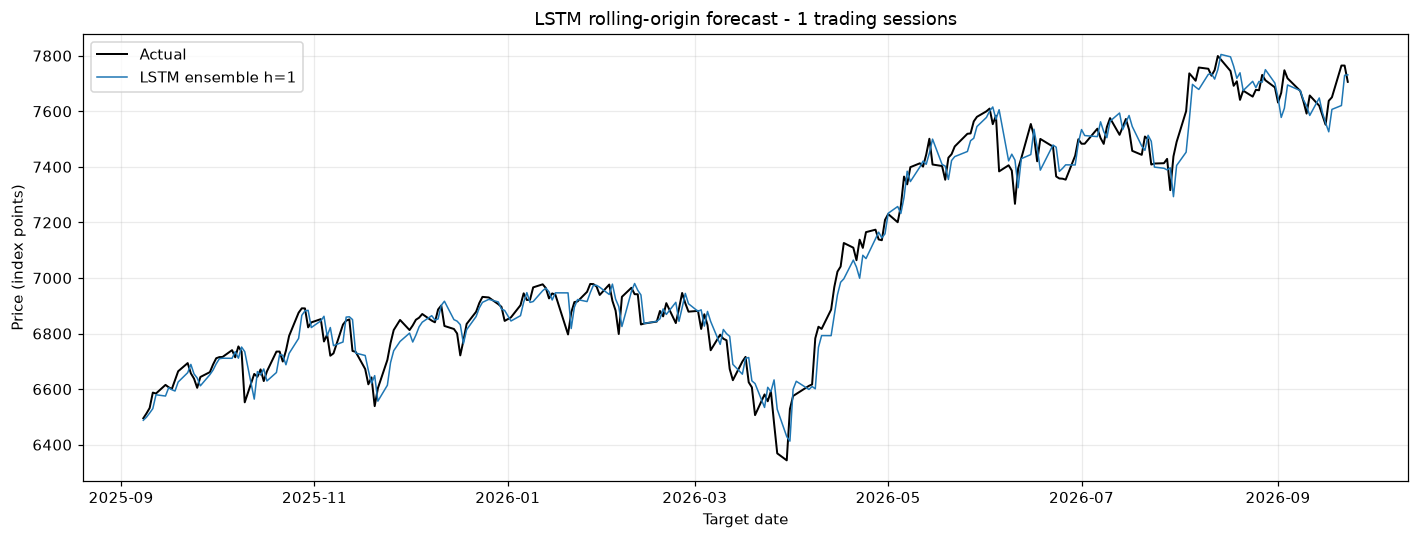

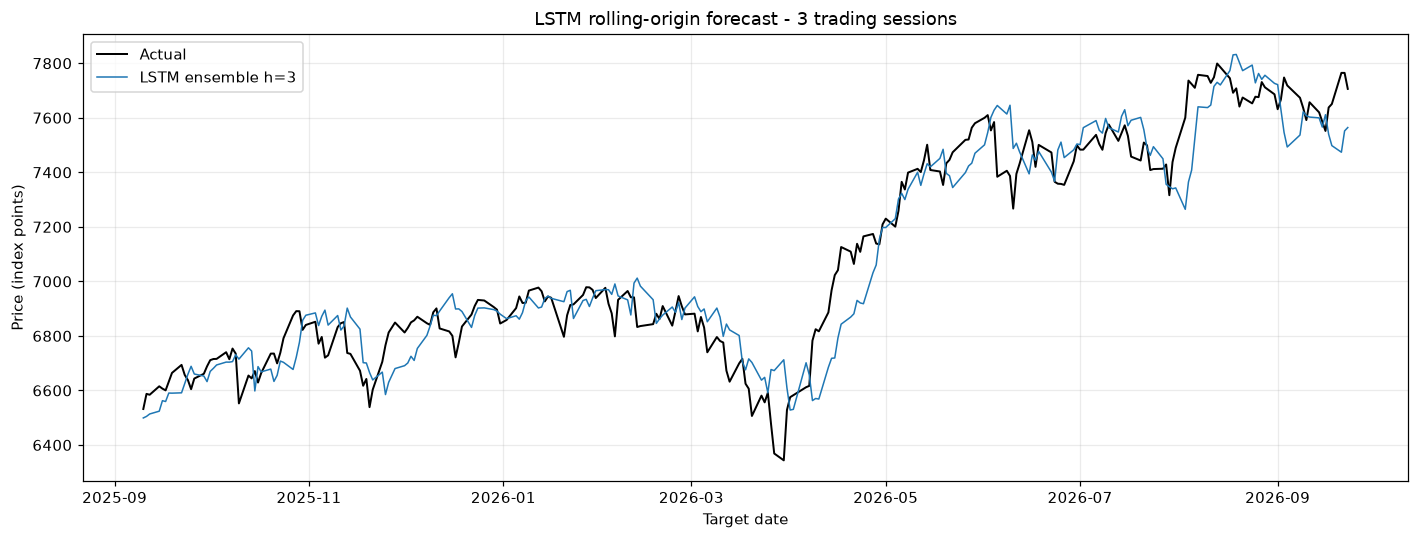

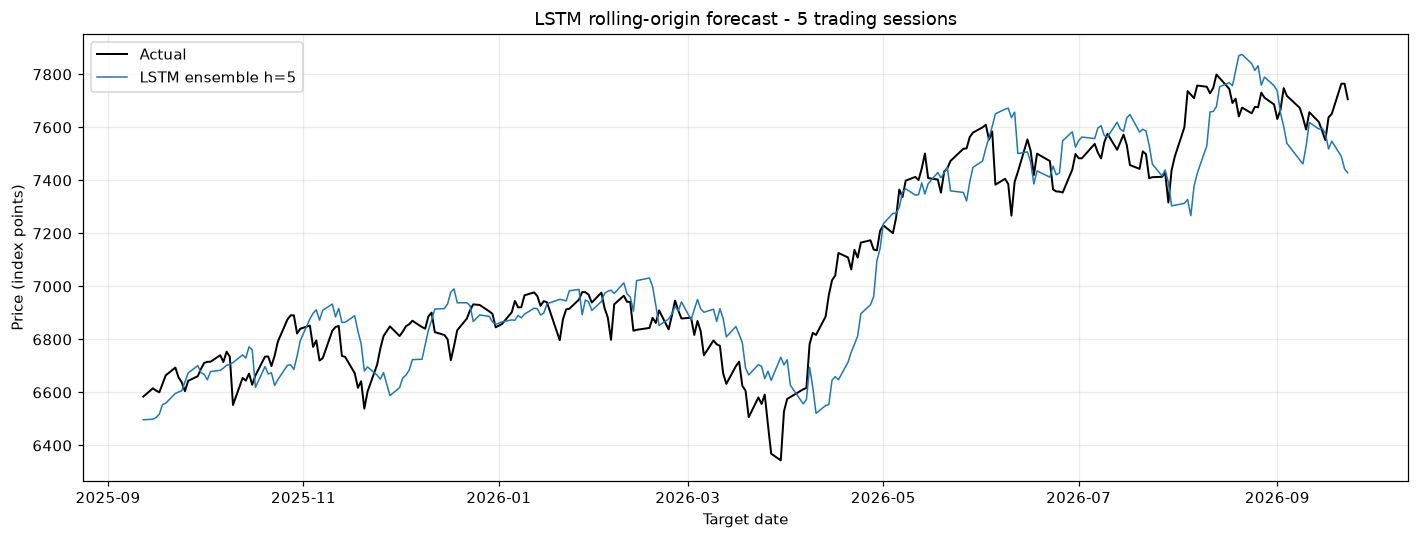

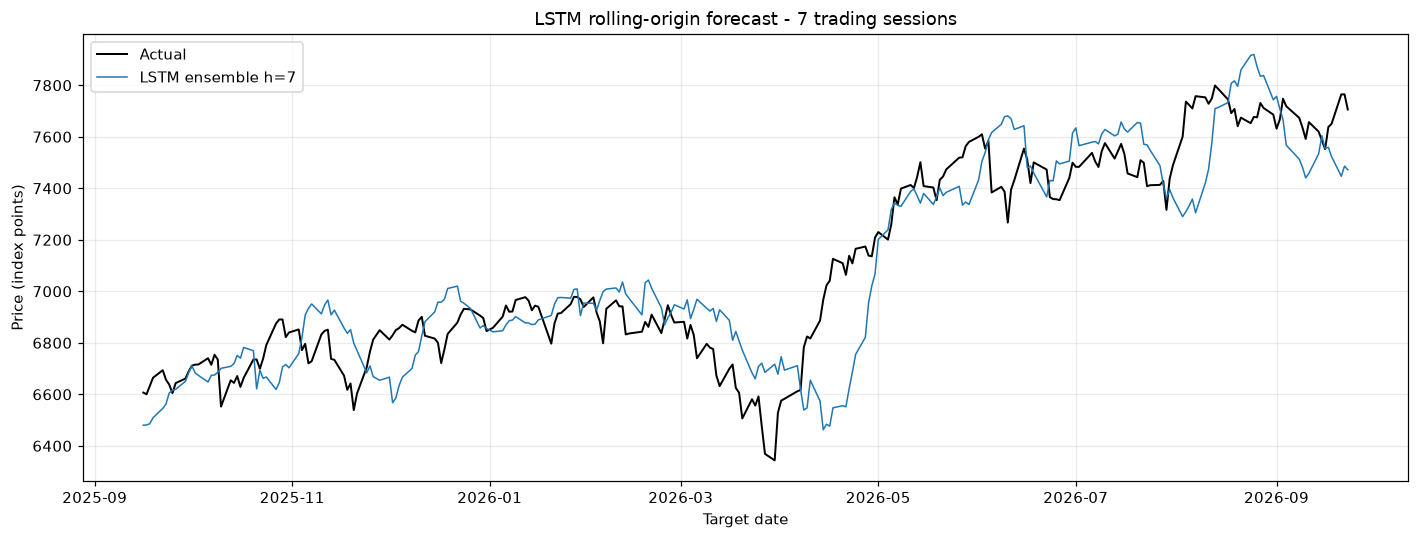

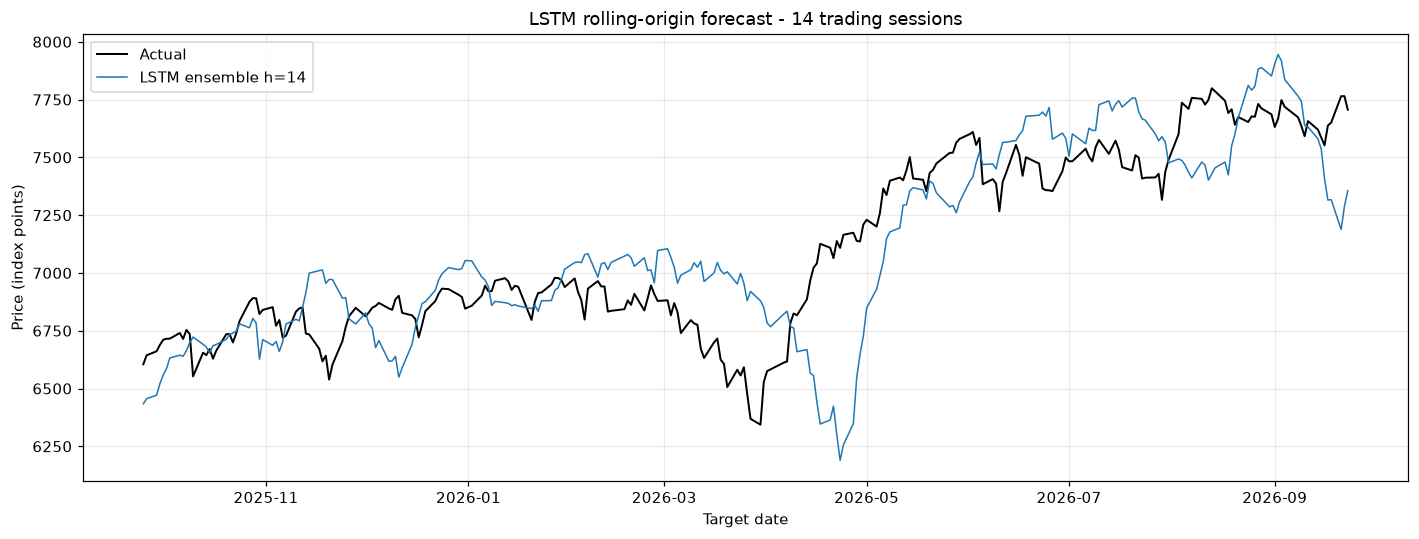

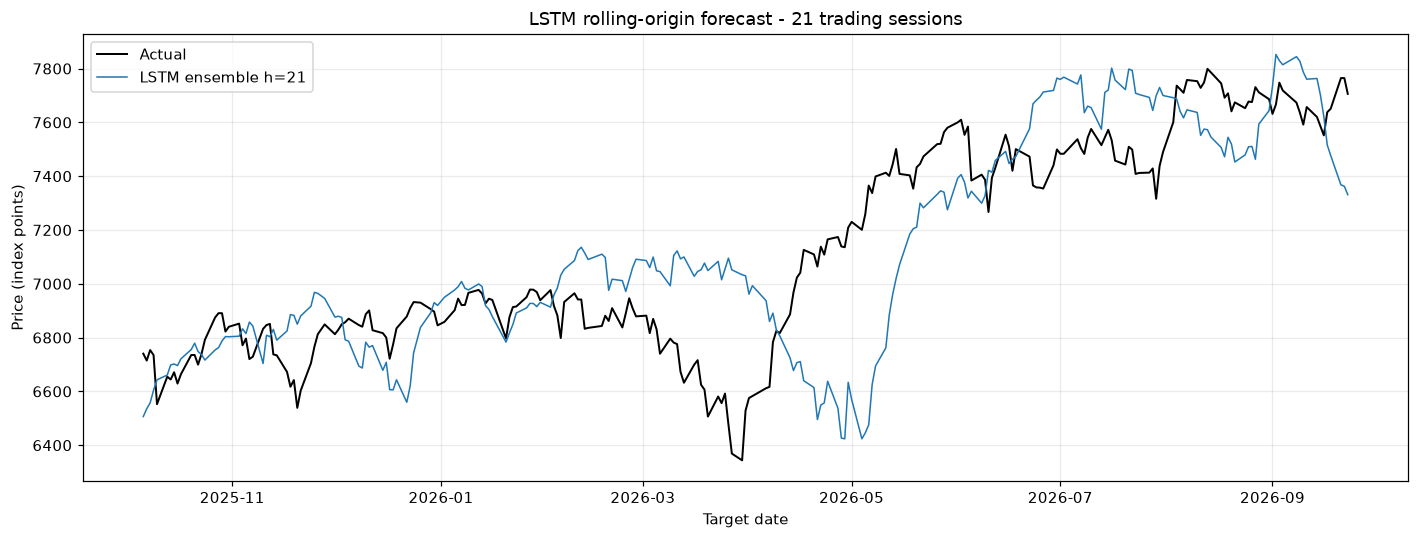

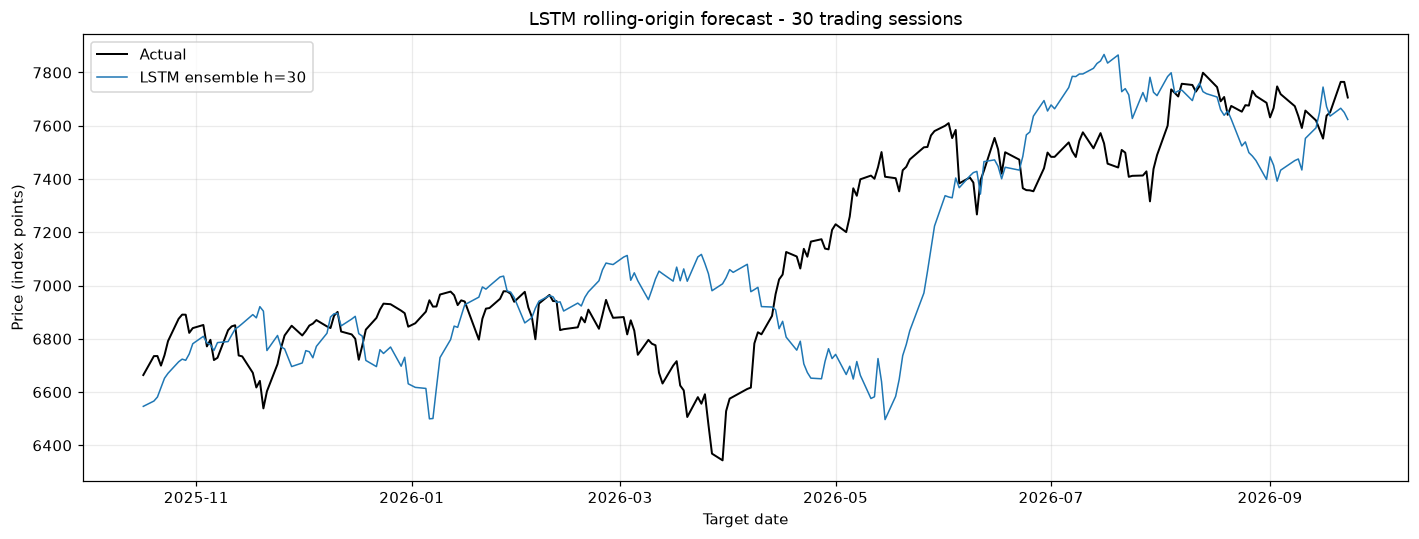

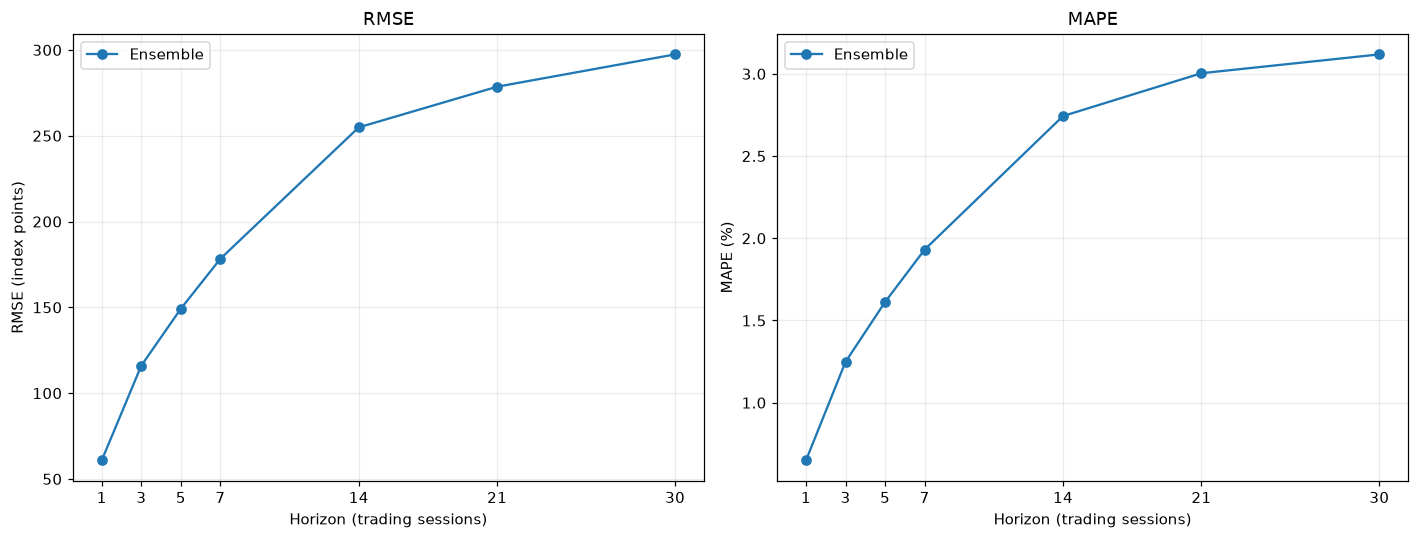

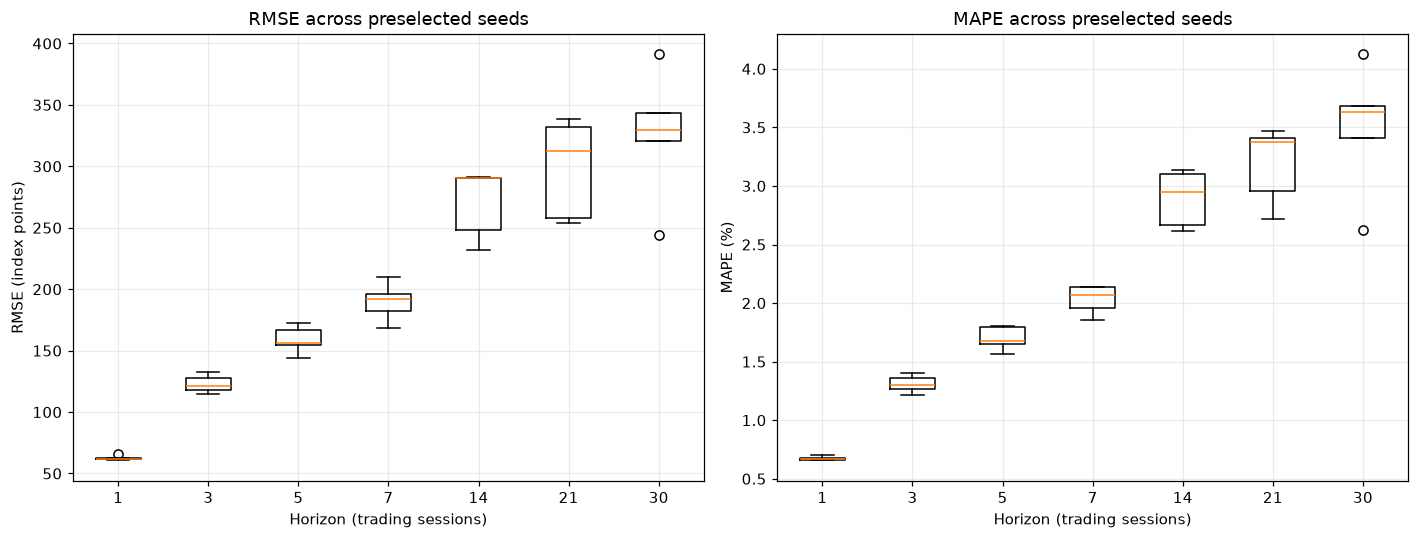

In [14]:
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.3)
    ax.plot(group['target_date'], group['lstm_fc_ens'], label=f'LSTM ensemble h={h}', linewidth=1)
    ax.set(title=f'LSTM rolling-origin forecast - {h} trading sessions', ylabel='Price (index points)', xlabel='Target date')
    ax.legend()
    save_figure(fig, f'07_forecast_h{h}.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['index points','%']):
    ax.plot(evaluation['h'], evaluation[metric], marker='o', label='Ensemble')
    ax.set(title=metric, xlabel='Horizon (trading sessions)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
    ax.legend()
save_figure(fig, '08_error_vs_horizon.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['index points','%']):
    values = [evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h),metric].to_numpy()
              for h in HORIZONS]
    ax.boxplot(values, tick_labels=[str(h) for h in HORIZONS])
    ax.set(title=f'{metric} across preselected seeds', xlabel='Horizon (trading sessions)', ylabel=f'{metric} ({unit})')
save_figure(fig, '09_seed_variability.png')

## Step 11 - Assumption and Process Checks
Group A structural checks are enforced where data/scaling/windowing/training occur and checked again here.
Mean/std comparability and seed stability are reported descriptively: the specification supplies no numerical acceptance threshold, so their status is REPORTED, not an invented pass/fail rule. Test distributions and seed metrics never alter the model.
Group B diagnoses h=1 ensemble errors on the unscaled log-return target, not index points price errors. Results are reporting-only.
LSTM does not require ARIMA root conditions or normal residuals as a training prerequisite.


Group A finite-loss and structural checks are enforced. Loss reduction and distribution/seed stability are descriptive; no new threshold is imposed. Group B diagnoses h=1 Test log-return errors only and never changes the fitted design.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Train windows exclude test,1049.000000,NaN,PASS,All inputs/targets <= 1049
2,A,Scaler fit excludes test,1049.000000,NaN,PASS,
3,A,Fixed inference weights,1.000000,NaN,PASS,
4,A,Train/test return mean and SD,0.723120,NaN,REPORTED,"Train mean=0.000386768, SD=0.0111189; Test mea..."
5,A,Training loss reduced: seed 0,0.818900,NaN,REPORTED,First=1.05701; final=0.865584; reduced=True; f...
6,A,Training loss reduced: seed 1,0.825009,NaN,REPORTED,First=1.05683; final=0.871898; reduced=True; f...
7,A,Training loss reduced: seed 2,0.842704,NaN,REPORTED,First=1.05739; final=0.891069; reduced=True; f...
8,A,Training loss reduced: seed 3,0.834969,NaN,REPORTED,First=1.05715; final=0.882686; reduced=True; f...
9,A,Training loss reduced: seed 4,0.833670,NaN,REPORTED,First=1.05732; final=0.881453; reduced=True; f...


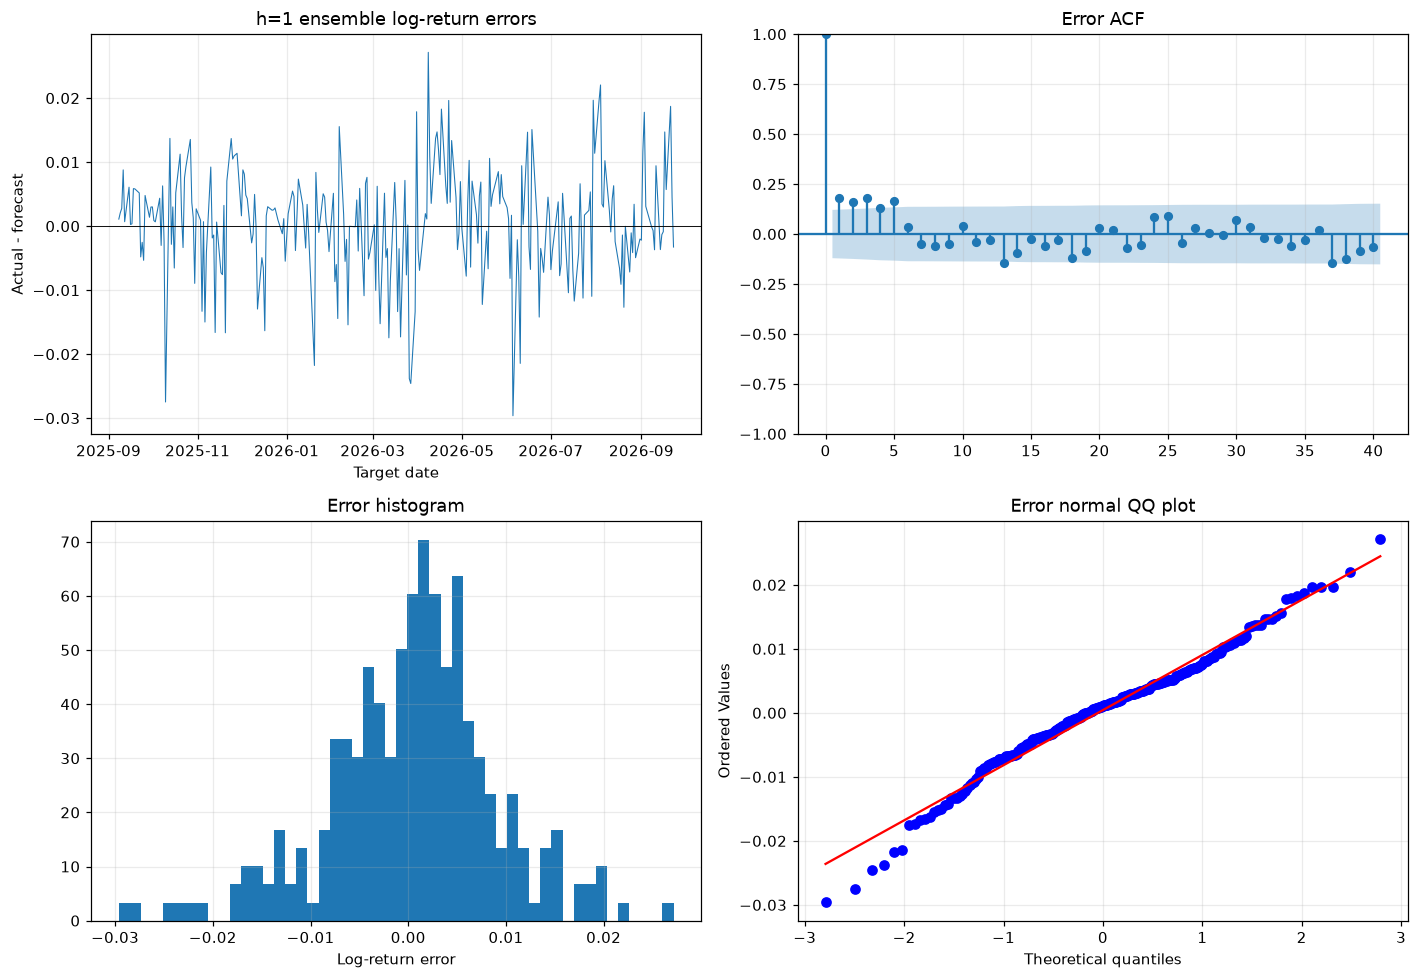

In [15]:
check_rows = []
def add_check(group, check, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    status = 'REPORTED' if passed is None else ('PASS' if bool(passed) else 'FAIL')
    check_rows.append({'group':group, 'check':check, 'statistic':statistic,
                       'p_value':p_value, 'pass/fail':status, 'note':note})
ordered = df.index.is_monotonic_increasing and df.index.is_unique
no_leak = train_input_indices.max() <= TRAIN_END_IDX and train_target_indices.max() <= TRAIN_END_IDX
scaler_train_only = scaler_fit_indices.max() <= TRAIN_END_IDX and int(scaler.n_samples_seen_) == n_train-1
add_check('A','Chronological unique dates', int(ordered), passed=ordered)
add_check('A','Train windows exclude test', int(train_target_indices.max()), passed=no_leak,
          note=f'All inputs/targets <= {TRAIN_END_IDX}')
add_check('A','Scaler fit excludes test', int(scaler_fit_indices.max()), passed=scaler_train_only)
add_check('A','Fixed inference weights', int(weight_audit['unchanged'].all()), passed=weight_audit['unchanged'].all())
train_stats = split_summary.set_index('split').loc['Train']
test_stats = split_summary.set_index('split').loc['Test']
add_check('A','Train/test return mean and SD', float(test_stats['log_ret_std']/train_stats['log_ret_std']),
    note=f'Train mean={train_stats["log_ret_mean"]:.6g}, SD={train_stats["log_ret_std"]:.6g}; '
         f'Test mean={test_stats["log_ret_mean"]:.6g}, SD={test_stats["log_ret_std"]:.6g}. '
         'Statistic=Test/Train SD ratio; no acceptance threshold specified.')
for row in training_audit.itertuples(index=False):
    add_check('A',f'Training loss reduced: seed {row.seed}', row.final_loss/row.first_loss,
        passed=None, note=f'First={row.first_loss:.6g}; final={row.final_loss:.6g}; reduced={row.loss_reduced}; fixed {EPOCHS} epochs; reporting only')
for row in seed_summary.itertuples(index=False):
    add_check('A',f'Seed RMSE SD: h={row.h}', row.RMSE_SD,
              note=f'index points, sample SD across {len(SEEDS)} seeds; no threshold specified')
    add_check('A',f'Seed MAPE SD: h={row.h}', row.MAPE_SD,
              note=f'Percentage points, sample SD across {len(SEEDS)} seeds; no threshold specified')
assert ordered and no_leak and scaler_train_only and weight_audit['unchanged'].all()
assert np.isfinite(seed_summary.select_dtypes('number').to_numpy()).all()

error_dates = df.index[test_origins+1]
e = log_ret.iloc[test_origins+1].to_numpy() - return_predictions_ens[:len(test_origins),0]
assert len(e) == n_test and np.isfinite(e).all()
ljung_box = acorr_ljungbox(e, lags=[10,20,30], return_df=True)
for lag,row in ljung_box.iterrows():
    add_check('B',f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'], row['lb_pvalue'] > ALPHA,
              'If significant, errors retain autocorrelation; reporting only')
mean_stat, mean_p = stats.ttest_1samp(e, 0)
add_check('B','Residual mean = 0', mean_stat, mean_p, mean_p > ALPHA,
          f'Mean error={e.mean():.6g}; if significant, forecast bias; reporting only')
arch_stat, arch_p, _, _ = het_arch(e, nlags=10)
add_check('B','ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA,
          'If significant, error variance changes over time; reporting only')
jb_stat, jb_p, skew, kurt = jarque_bera(e)
add_check('B','Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
          f'skew={skew:.4g}, kurtosis={kurt:.4g}; reporting only')
assumption_checks = pd.DataFrame(check_rows)
save_table(assumption_checks, 'assumption_checks.csv')
save_table(pd.DataFrame({'target_date':error_dates, 'actual_log_return':log_ret.iloc[test_origins+1].to_numpy(),
    'predicted_log_return':return_predictions_ens[:len(test_origins),0], 'residual':e}), 'residuals_h1.csv')
display(assumption_checks)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].plot(error_dates, e, linewidth=0.7)
axes[0,0].axhline(0, color='black', linewidth=0.6)
axes[0,0].set(title='h=1 ensemble log-return errors', xlabel='Target date', ylabel='Actual - forecast')
plot_acf(e, lags=40, ax=axes[0,1]); axes[0,1].set_title('Error ACF')
axes[1,0].hist(e, bins=50, density=True); axes[1,0].set(title='Error histogram', xlabel='Log-return error')
stats.probplot(e, dist='norm', plot=axes[1,1]); axes[1,1].set_title('Error normal QQ plot')
save_figure(fig, '10_residual_diagnostics.png')

## Step 12 - Summary
The next cell reports the fixed training settings, all process and residual checks, and RMSE/MAPE for every horizon.
It keeps ensemble performance separate from mean +/- SD across seeds. No performance result is used to select a seed, architecture, or epoch count.
A saved Markdown summary from the verified full execution appears below it.


In [16]:
FORECAST_COLUMN='lstm_fc_ens'
lines = [f'### S&P 500 - {MODEL_LABEL} results from this execution', '',
    f'Data: {n:,} observed NYSE sessions, {df.index[0].date()} to {df.index[-1].date()}.',
    f'Raw Train/Test={n_train}/{n_test}; Train ends {df.index[TRAIN_END_IDX].date()}, Test starts {df.index[n_train].date()}.',
    f'Horizons={HORIZONS} trading sessions; inputs={LOOKBACK} past session returns; original target units=index points.',
    'No validation, cross-validation, Test tuning, early stopping, seed selection or all-data refit.',
    'Previously observed Test history updates inputs only; fitted parameters and preprocessing remain fixed.',
    '', '**Configuration fixed before Test evaluation**', '```json', json.dumps(configuration,indent=2,default=str), '```',
    '', '**Assumption/process checks**']
for row in assumption_checks.to_dict('records'):
    ptext=f', p={row["p_value"]:.6g}' if pd.notna(row['p_value']) else ''
    lines.append(f'- Group {row["group"]}: {row["check"]}: {row["pass/fail"]}{ptext}. {row["note"]}')
lines += ['', '**Historical Test performance**', '',
    '| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |','|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} |')
if 'seed_summary' in globals():
    lines += ['', '**All predefined seeds: metric mean and sample SD (different from ensemble performance)**','',
        '| Horizon | Seed RMSE mean +/- SD (points) | Seed MAPE mean +/- SD (%) |','|---:|---:|---:|']
    for row in seed_summary.itertuples(index=False):
        lines.append(f'| {row.h} | {row.RMSE_mean:.2f} +/- {row.RMSE_SD:.2f} | {row.MAPE_mean:.2f} +/- {row.MAPE_SD:.2f} |')
lines += ['', '**Future forecasts: common latest observed origin, fixed Train model**']
for row in future_forecasts.to_dict('records'):
    lines.append(f'- h={row["h"]}: origin={row["origin_date"].date()}, target={row["target_date"].date()}, forecast={row[FORECAST_COLUMN]:,.2f} points.')
lines += ['', '**Limitations and interpretation**',
    '- Future means dates after the final CSV observation, not necessarily dates after today. These rows have no actuals or error metrics.',
    '- Train fit and loss reductions are optimistic fitting diagnostics, not proof of generalization. There is no independent validation estimate.',
    '- Group A structural checks enforce chronology/leakage/frozen state. Distribution comparisons, seed variability and loss-reduction summaries are descriptive where no threshold is supplied.',
    '- Group B h=1 log-return residual tests report autocorrelation, bias, changing variance and non-normality; significant results do not discard or retune models.',
    '- No ARIMA stationarity/root conditions are imposed on this model family.',
    '- Different horizons have different targets/counts and overlapping errors. MAPE is error percent; 100-MAPE is not statistical accuracy.',
    '- Univariate Price-derived returns do not observe news, policy changes, interest rates, inflation or unexpected events.',
    '- No calibrated prediction intervals are provided; seed dispersion, if present, is not a prediction interval.',
    '- All source rows are retained. Volume is missing and unused. No weekend/holiday observations or targets were imputed.',
    '- Session calendar covers 2021-2027 scheduled NYSE closures, including 9 January 2025; early-close days remain sessions. Unexpected closures can change future dates.',
    '- Tables, figures and this summary are embedded in this existing notebook; no additional files or model exports are written. Trained models remain in memory during the session.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary_markdown='\n'.join(lines)
display(Markdown(summary_markdown))
# Final audits; no additional fitting or design revision.
assert n_train==int(0.8*n) and n_train+n_test==n
assert forecasts.groupby('h').size().to_dict()=={h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert forecasts.target_date.between(df.index[n_train],df.index[-1]).all()
assert (df.index.get_indexer(forecasts.target_date)-df.index.get_indexer(forecasts.origin_date)==forecasts.h.to_numpy()).all()
assert (future_forecasts.origin_date==df.index[-1]).all()
assert future_forecasts.target_date.tolist()==[future_dates[h-1] for h in HORIZONS]
assert np.isfinite(evaluation[['RMSE','MAPE']]).all().all()
assert not len(missing_sessions) and not len(unexpected_dates)
assert not assumption_checks.loc[assumption_checks.group.eq('A'),'pass/fail'].eq('FAIL').any()
for name in ['split_summary.csv','calendar_audit.csv','forecasts_long.csv','evaluation_by_horizon.csv','future_forecast_by_horizon.csv','assumption_checks.csv',*[f'forecasts_h{h}.csv' for h in HORIZONS]]:
    assert name in notebook_tables,name
assert scaler_digest(scaler)==frozen_scaler_hash
assert all(weights_digest(models[seed])==frozen_weight_hashes[seed] for seed in SEEDS)
display(Markdown('### Full supplementary table archive (stored in this notebook)'))
for name, frame in notebook_tables.items():
    if name.startswith('forecasts') or name in ['evaluation_by_horizon.csv','future_forecast_by_horizon.csv','assumption_checks.csv','volume_B_rows.csv']:
        continue
    display(Markdown(f'**{name.removesuffix(".csv")}**'))
    show_scroll_table(frame)
print(f'Completed: {MODEL_LABEL}; {len(notebook_tables)} tables retained, {len(notebook_figures)} figures; all structural checks passed.')

### S&P 500 - LSTM results from this execution

Data: 1,313 observed NYSE sessions, 2021-07-01 to 2026-09-23.
Raw Train/Test=1050/263; Train ends 2025-09-05, Test starts 2025-09-08.
Horizons=[1, 3, 5, 7, 14, 21, 30] trading sessions; inputs=60 past session returns; original target units=index points.
No validation, cross-validation, Test tuning, early stopping, seed selection or all-data refit.
Previously observed Test history updates inputs only; fitted parameters and preprocessing remain fixed.

**Configuration fixed before Test evaluation**
```json
{
  "HORIZONS": [
    1,
    3,
    5,
    7,
    14,
    21,
    30
  ],
  "MAX_H": 30,
  "LOOKBACK": 60,
  "TRAIN_RATIO": 0.8,
  "ALPHA": 0.05,
  "EPOCHS": 50,
  "BATCH_SIZE": 32,
  "LR": 0.001,
  "DROPOUT": 0.1,
  "SEEDS": [
    0,
    1,
    2,
    3,
    4
  ],
  "asset": "S&P 500",
  "target": "Price",
  "units": "index points",
  "horizon_unit": "trading sessions",
  "validation": false,
  "output_mode": "notebook only",
  "source_reference": "BTC_TEST/LSTM_BTC.ipynb"
}
```

**Assumption/process checks**
- Group A: Chronological unique dates: PASS. 
- Group A: Train windows exclude test: PASS. All inputs/targets <= 1049
- Group A: Scaler fit excludes test: PASS. 
- Group A: Fixed inference weights: PASS. 
- Group A: Train/test return mean and SD: REPORTED. Train mean=0.000386768, SD=0.0111189; Test mean=0.000657989, SD=0.0080403. Statistic=Test/Train SD ratio; no acceptance threshold specified.
- Group A: Training loss reduced: seed 0: REPORTED. First=1.05701; final=0.865584; reduced=True; fixed 50 epochs; reporting only
- Group A: Training loss reduced: seed 1: REPORTED. First=1.05683; final=0.871898; reduced=True; fixed 50 epochs; reporting only
- Group A: Training loss reduced: seed 2: REPORTED. First=1.05739; final=0.891069; reduced=True; fixed 50 epochs; reporting only
- Group A: Training loss reduced: seed 3: REPORTED. First=1.05715; final=0.882686; reduced=True; fixed 50 epochs; reporting only
- Group A: Training loss reduced: seed 4: REPORTED. First=1.05732; final=0.881453; reduced=True; fixed 50 epochs; reporting only
- Group A: Seed RMSE SD: h=1: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=1: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=3: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=3: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=5: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=5: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=7: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=7: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=14: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=14: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=21: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=21: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=30: REPORTED. index points, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=30: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group B: Ljung-Box lag 10: FAIL, p=2.26034e-05. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 20: FAIL, p=2.61495e-05. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 30: FAIL, p=0.000183424. If significant, errors retain autocorrelation; reporting only
- Group B: Residual mean = 0: PASS, p=0.415626. Mean error=0.000434326; if significant, forecast bias; reporting only
- Group B: ARCH LM (10 lags): PASS, p=0.567205. If significant, error variance changes over time; reporting only
- Group B: Jarque-Bera: FAIL, p=0.000181744. skew=-0.3345, kurtosis=4.06; reporting only

**Historical Test performance**

| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |
|---:|---:|---:|---:|
| 1 | 263 | 60.85 | 0.65 |
| 3 | 261 | 116.04 | 1.25 |
| 5 | 259 | 149.19 | 1.61 |
| 7 | 257 | 178.31 | 1.93 |
| 14 | 250 | 254.90 | 2.74 |
| 21 | 243 | 278.59 | 3.00 |
| 30 | 234 | 297.42 | 3.12 |

**All predefined seeds: metric mean and sample SD (different from ensemble performance)**

| Horizon | Seed RMSE mean +/- SD (points) | Seed MAPE mean +/- SD (%) |
|---:|---:|---:|
| 1 | 62.67 +/- 2.03 | 0.67 +/- 0.02 |
| 3 | 122.87 +/- 7.51 | 1.31 +/- 0.07 |
| 5 | 158.87 +/- 10.93 | 1.70 +/- 0.10 |
| 7 | 189.73 +/- 15.46 | 2.03 +/- 0.12 |
| 14 | 270.48 +/- 28.09 | 2.89 +/- 0.24 |
| 21 | 299.03 +/- 40.25 | 3.19 +/- 0.33 |
| 30 | 325.80 +/- 53.05 | 3.49 +/- 0.55 |

**Future forecasts: common latest observed origin, fixed Train model**
- h=1: origin=2026-09-23, target=2026-09-24, forecast=7,679.72 points.
- h=3: origin=2026-09-23, target=2026-09-28, forecast=7,626.31 points.
- h=5: origin=2026-09-23, target=2026-09-30, forecast=7,606.07 points.
- h=7: origin=2026-09-23, target=2026-10-02, forecast=7,632.41 points.
- h=14: origin=2026-09-23, target=2026-10-13, forecast=7,842.78 points.
- h=21: origin=2026-09-23, target=2026-10-22, forecast=7,718.96 points.
- h=30: origin=2026-09-23, target=2026-11-04, forecast=7,607.61 points.

**Limitations and interpretation**
- Future means dates after the final CSV observation, not necessarily dates after today. These rows have no actuals or error metrics.
- Train fit and loss reductions are optimistic fitting diagnostics, not proof of generalization. There is no independent validation estimate.
- Group A structural checks enforce chronology/leakage/frozen state. Distribution comparisons, seed variability and loss-reduction summaries are descriptive where no threshold is supplied.
- Group B h=1 log-return residual tests report autocorrelation, bias, changing variance and non-normality; significant results do not discard or retune models.
- No ARIMA stationarity/root conditions are imposed on this model family.
- Different horizons have different targets/counts and overlapping errors. MAPE is error percent; 100-MAPE is not statistical accuracy.
- Univariate Price-derived returns do not observe news, policy changes, interest rates, inflation or unexpected events.
- No calibrated prediction intervals are provided; seed dispersion, if present, is not a prediction interval.
- All source rows are retained. Volume is missing and unused. No weekend/holiday observations or targets were imputed.
- Session calendar covers 2021-2027 scheduled NYSE closures, including 9 January 2025; early-close days remain sessions. Unexpected closures can change future dates.
- Tables, figures and this summary are embedded in this existing notebook; no additional files or model exports are written. Trained models remain in memory during the session.

**Daily future forecasts**
Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

### Full supplementary table archive (stored in this notebook)

**library_versions**

library,version
pandas,2.3.3
numpy,2.5.3
matplotlib,3.11.1
scikit-learn,1.9.1
statsmodels,0.15.0
scipy,1.18.1
tensorflow,2.21.0
keras,3.15.1


**calendar_audit**

...

**evaluation_by_seed**

h,seed,RMSE,MAPE
1,0,61.8978,0.6600
1,1,60.6985,0.6573
1,2,66.0188,0.6990
1,3,62.8988,0.6794
1,4,61.8532,0.6672
1,mean,62.6734,0.6726
1,SD,2.0259,0.0171
3,0,117.6954,1.2678
3,1,114.6097,1.2172
3,2,132.8927,1.4047


**residuals_h1**

target_date,actual_log_return,predicted_log_return,residual
2025-09-08,0.0021,0.0010,0.0011
2025-09-09,0.0027,0.0006,0.0021
2025-09-10,0.0030,0.0002,0.0028
2025-09-11,0.0085,-0.0003,0.0088
2025-09-12,-0.0005,-0.0012,0.0007
2025-09-15,0.0047,-0.0014,0.0061
2025-09-16,-0.0013,-0.0015,0.0003
2025-09-17,-0.0010,-0.0013,0.0004
2025-09-18,0.0048,-0.0011,0.0059
2025-09-19,0.0049,-0.0009,0.0058


Completed: LSTM; 24 tables retained, 16 figures; all structural checks passed.


## Implementation and calendar references

Local model example: `BTC_TEST/LSTM_BTC.ipynb`. The architecture, analytical rules or fixed estimator settings follow this source, with S&P session dates, data quality and index-point units adapted explicitly.

- [NYSE holidays and trading hours](https://www.nyse.com/trade/hours-calendars)
- [NYSE special closure on 9 January 2025](https://www.nyse.com/publicdocs/nyse/markets/american-options/rule-interpretations/2025/National_Day_of_Mourning_20250102.pdf)
- [Keras LSTM](https://keras.io/api/layers/recurrent_layers/lstm/)

Referenced implementation material does not override the user's no-validation, no-Test-tuning protocol.